In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from em_clustering import (
    recursive_em_split, 
    reassign_cells
)

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
# 1. Load Data
infilename = "../data/t57.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep="\t")
bincounts_no_WGS = pd.read_csv("../data/t57.bincounts_without_WGS_segmentation.txt", sep="\t")


In [3]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGAGTTTGCGTCT,TTTTGGATTCCTAGAGA,TTTTGGGAACAATAAGC,TTTTGGGGGTTTTCAGA,TTTTGGGTCTTTAGTCG,TTTTGGGTCTTTCTACT,TTTTGGTAAGCTCAAGT,TTTTGGTGCAGGAATCA,TTTTGGTGCAGGAGAAG,TTTTGGTTTGGAAGTAC
0,chr1,0,45387037,0,45387037,570,1604,403,1325,853,...,214,1224,790,399,1536,1146,1064,961,16,834
1,chr1,45972336,119478274,45972336,119478274,928,5401,596,4437,2675,...,1421,2223,1209,593,4682,1092,671,3250,882,1429
2,chr1,120035598,175362842,120035598,175362842,506,2172,294,1671,1987,...,299,785,542,2015,1815,705,388,1264,2146,669
3,chr1,175900450,182029442,175900450,182029442,83,230,66,184,232,...,12,142,72,230,181,74,63,76,250,132
4,chr1,182578512,248389233,182578512,248389233,819,2760,612,1954,1335,...,152,1066,855,600,2012,1097,309,768,916,1228


In [4]:
bincounts_no_WGS.head()

,chrom,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGAGCGCGAAT,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,...,TTTTGGGGGTTTTCAGA,TTTTGGGTCTTTAGTCG,TTTTGGGTCTTTCTACT,TTTTGGGTGCAATGTCC,TTTTGGTAAGCTCAAGT,TTTTGGTATTCTAGTAC,TTTTGGTGCAGGAATCA,TTTTGGTGCAGGAGAAG,TTTTGGTTTGGAAGTAC,lengths
0,chr1,10001,30659098,455,1270,286,986,121,700,225,...,319,1114,894,656,877,872,703,17,633,30649097
1,chr1,30659098,56590788,328,1651,255,1314,38,839,192,...,229,1480,661,839,495,1042,900,184,628,25931690
2,chr1,56590788,78784430,316,2034,200,1705,523,1069,127,...,155,1620,370,981,155,1287,1115,380,542,22193642
3,chr1,78784432,101651329,312,1966,210,1572,463,963,175,...,237,1671,374,1017,463,1449,1122,314,511,22866897
4,chr1,101651353,143437314,338,2151,165,1476,386,978,151,...,341,1443,422,957,354,1368,1219,288,549,41785961


In [5]:
# Use ALL cells instead of filtered cells
all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]
cells = pd.read_csv("../data/t57.not_broken_final_list.txt", header=None)[0].values


In [6]:
# Prepare data
data = bincounts[["chrom", "abstart", "abend"] + all_cell_names].copy()
data["lengths"] = data["abend"] - data["abstart"]
all_data = data[cells].copy()
data_no_WGS = bincounts_no_WGS[["chrom", "abstart", "abend"] + all_cell_names].copy()
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]
all_data_no_WGS = data_no_WGS[cells].copy()


Running recursive EM split A...
Processing population A with 2533 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for A: max=2.654, min=0.389
Split accepted for A: 1743 + 790 cells
  Processing population A1 with 1743 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for A1: max=1.302, min=0.804
  Split rejected for A1: slopes between 0.750 and 1.333
  Processing population A2 with 790 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for A2: max=1.778, min=0.641
  Split accepted for A2: 365 + 425 cells
    Processing population A21 with 365 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying 

../src/em_clustering.py:46: RuntimeWarning: divide by zero encountered in log
  logmult_KV = np.log(mult_KV)


Trying new seed
Trying new seed
      Slopes for A221: max=1.908, min=0.816
      Split accepted for A221: 88 + 38 cells
        Processing population A2211 with 88 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
        Slopes for A2211: max=5.491, min=0.554
        Split produces too small subpopulations for A2211
        Processing population A2212 with 38 cells
        Population A2212 too small to split
      Processing population A222 with 299 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


../src/em_clustering.py:46: RuntimeWarning: divide by zero encountered in log
  logmult_KV = np.log(mult_KV)


Trying new seed
Trying new seed
      Slopes for A222: max=1.428, min=0.691
      Split accepted for A222: 54 + 245 cells
        Processing population A2221 with 54 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
        Slopes for A2221: max=1.416, min=0.648
        Split produces too small subpopulations for A2221
        Processing population A2222 with 245 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
        Slopes for A2222: max=1.187, min=0.750
        Split accepted for A2222: 130 + 115 cells
          Processing population A22221 with 130 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
          Slopes for A22221: max=1.235, m

../src/em_clustering.py:46: RuntimeWarning: divide by zero encountered in log
  logmult_KV = np.log(mult_KV)


Trying new seed
            Slopes for A222221: max=1.115, min=0.705
            Split produces too small subpopulations for A222221
            Processing population A222222 with 28 cells
            Population A222222 too small to split


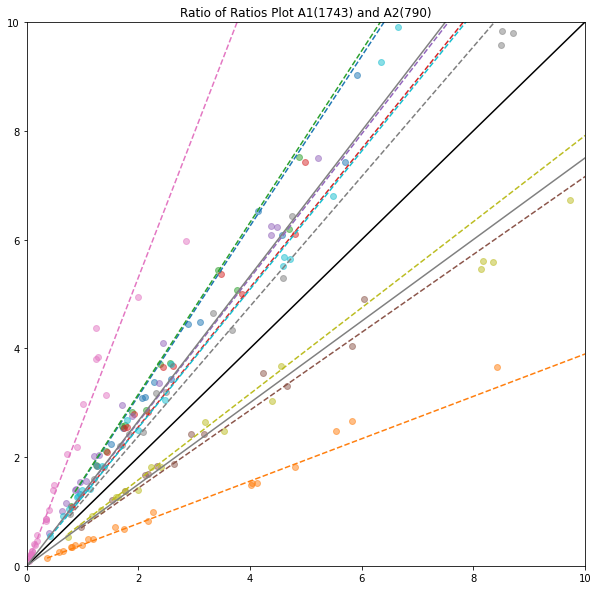

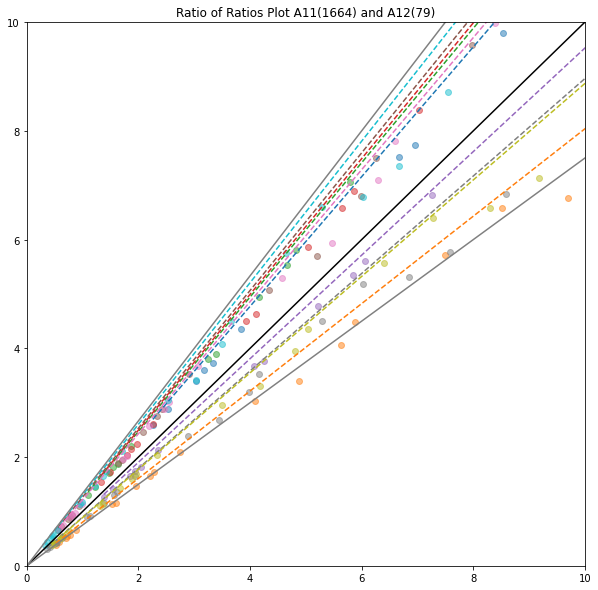

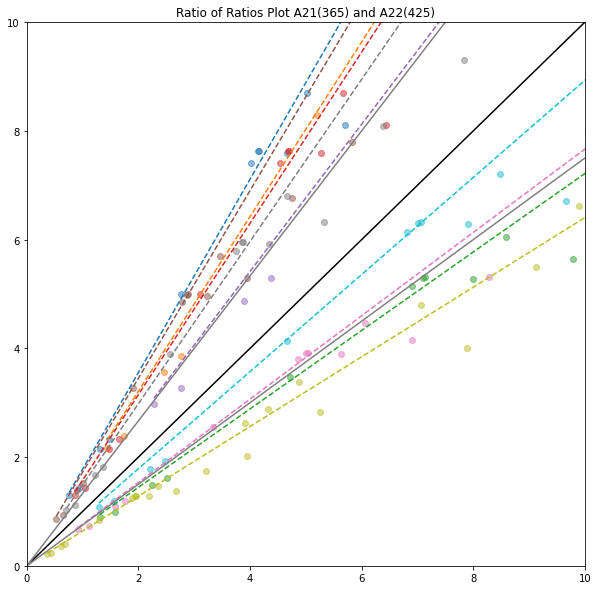

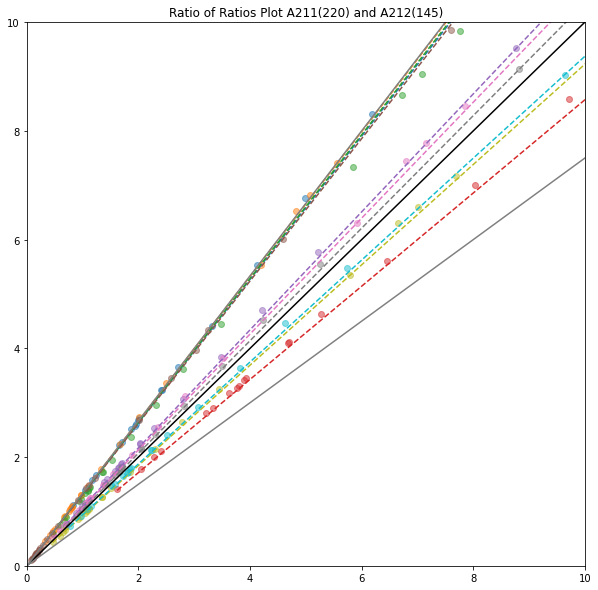

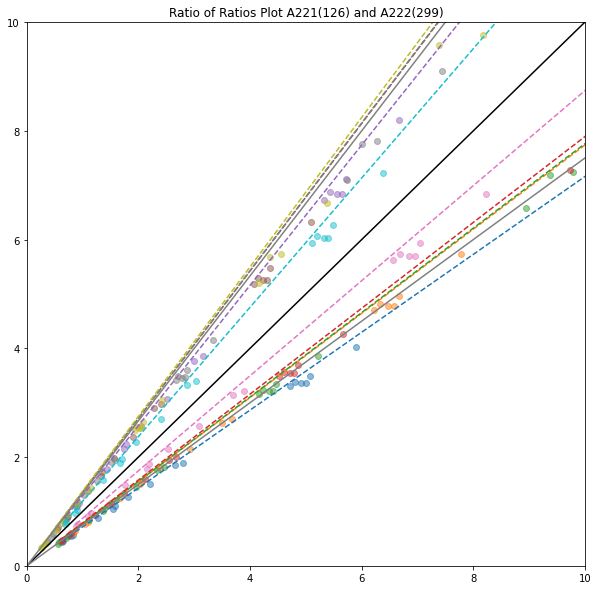

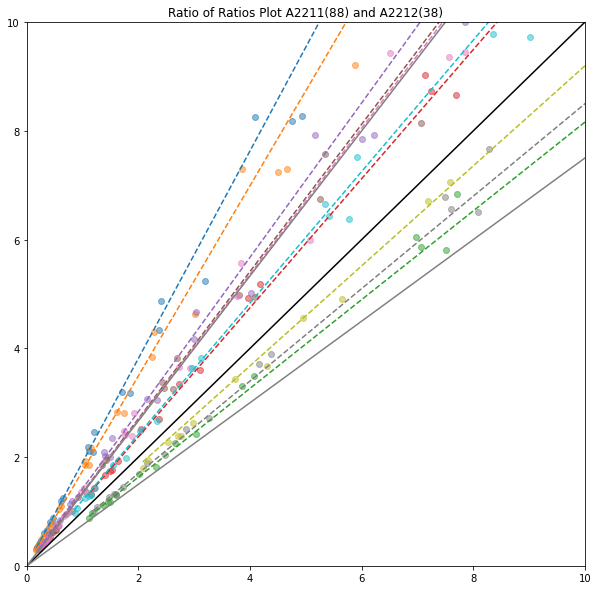

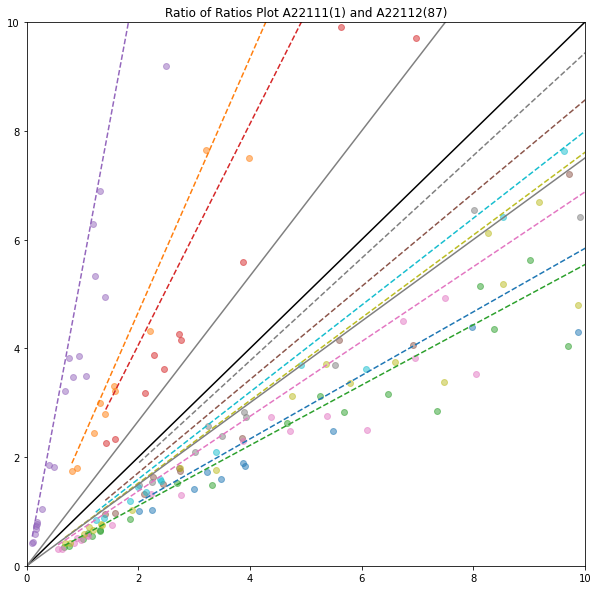

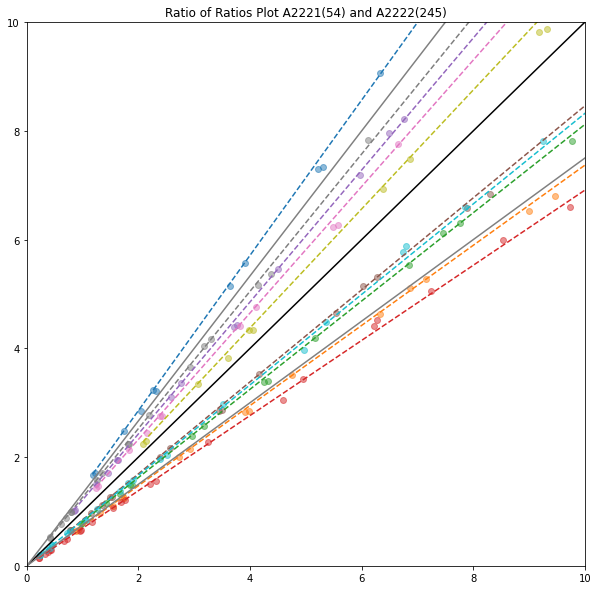

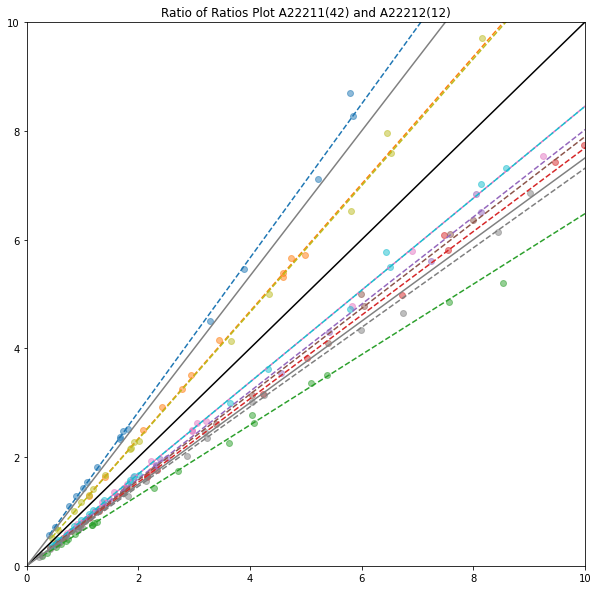

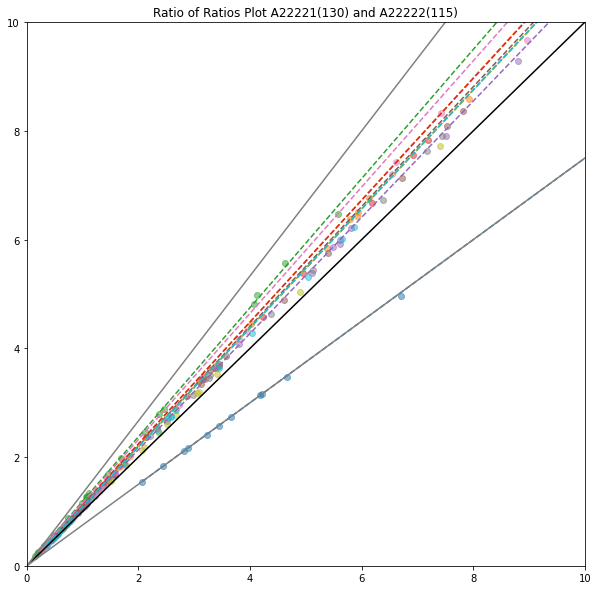

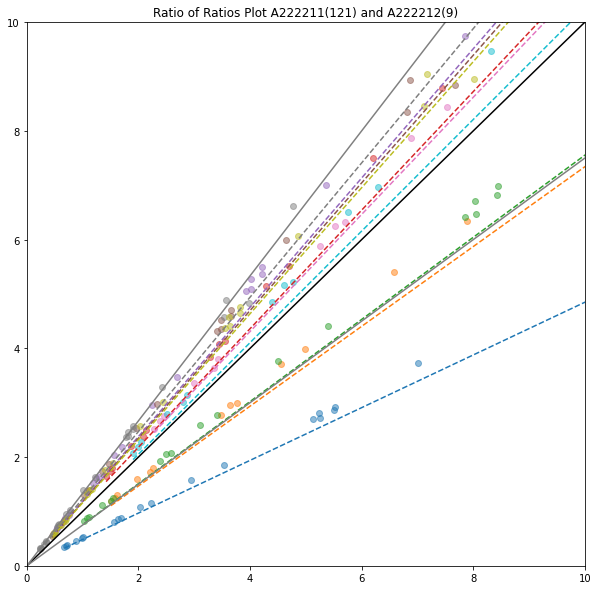

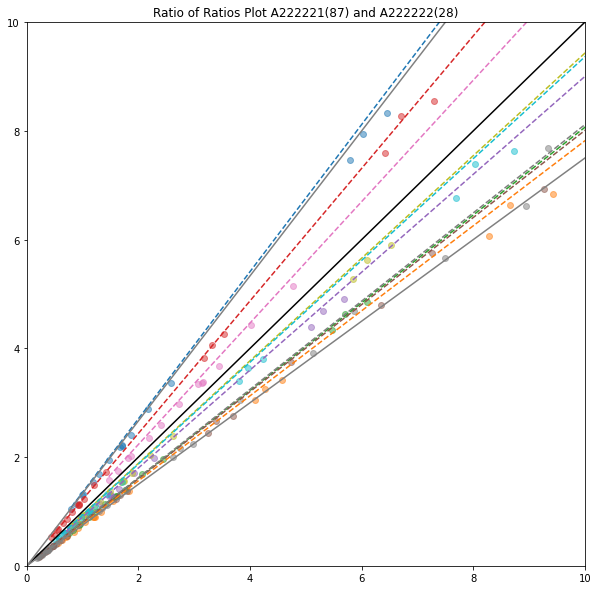

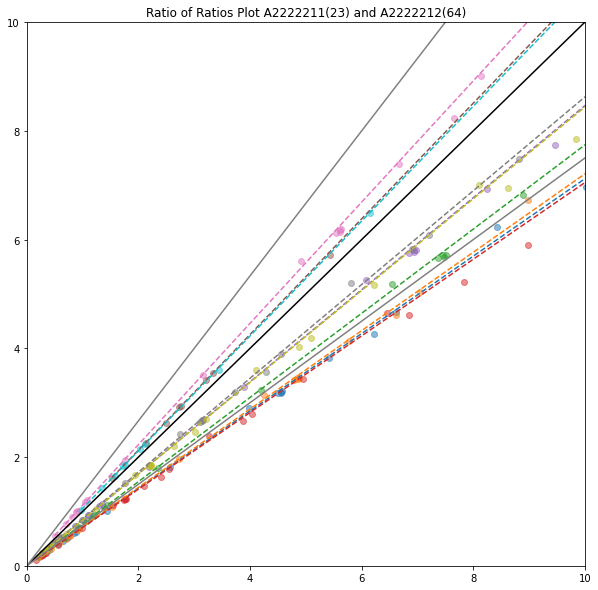

In [7]:
# 2. Run Recursive EM Splitting (two independent runs)
print("Running recursive EM split A...")
final_populations_A = recursive_em_split(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="A"
)

Processing population B with 2533 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for B: max=2.223, min=0.608
Split accepted for B: 789 + 1744 cells
  Processing population B1 with 789 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for B1: max=1.745, min=0.644
  Split accepted for B1: 362 + 427 cells
    Processing population B11 with 362 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
    Slopes for B11: max=1.357, min=0.852
    Split accepted for B11: 218 + 144 cells
      Processing population B111 with 218 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new 

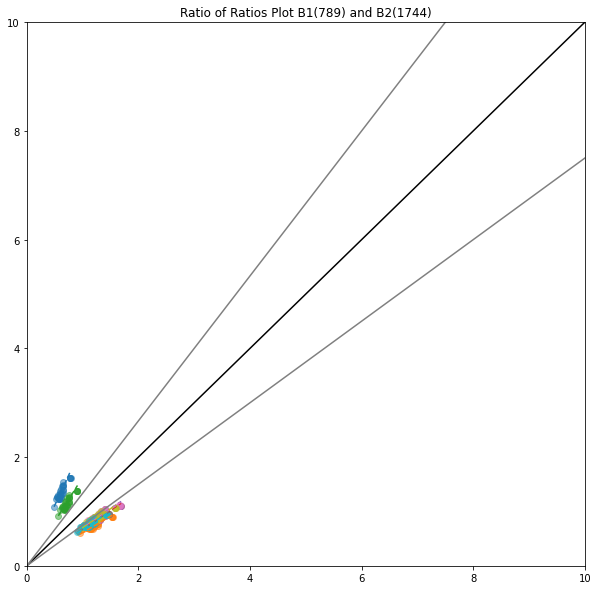

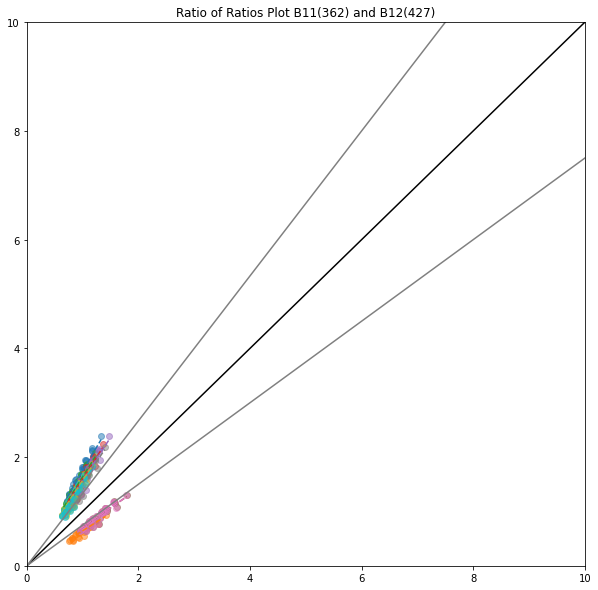

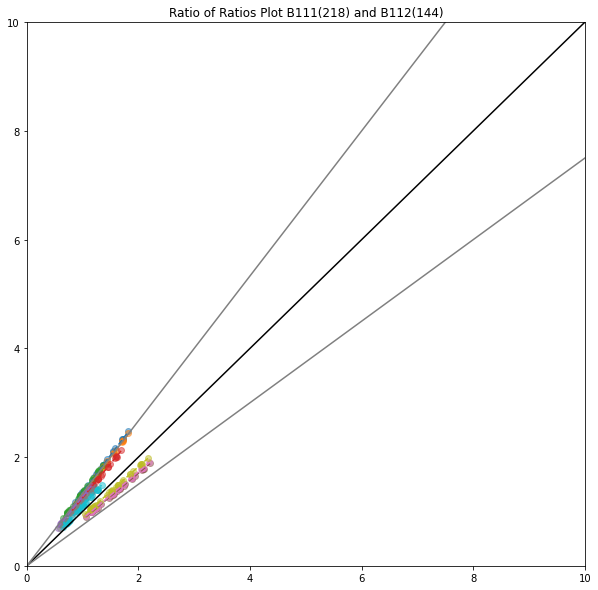

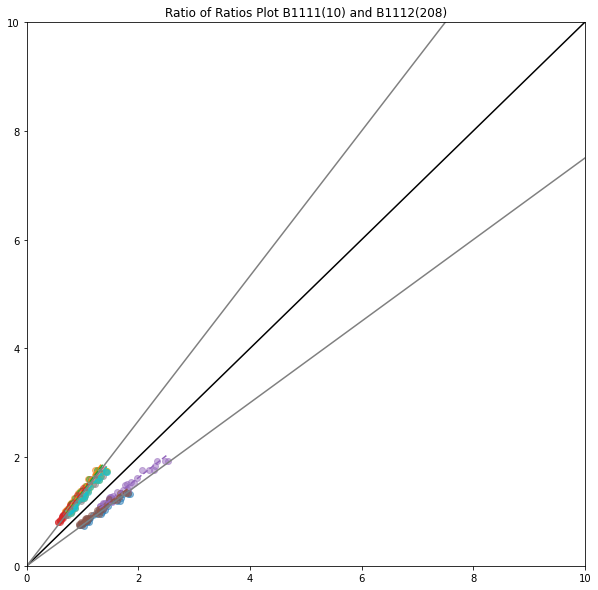

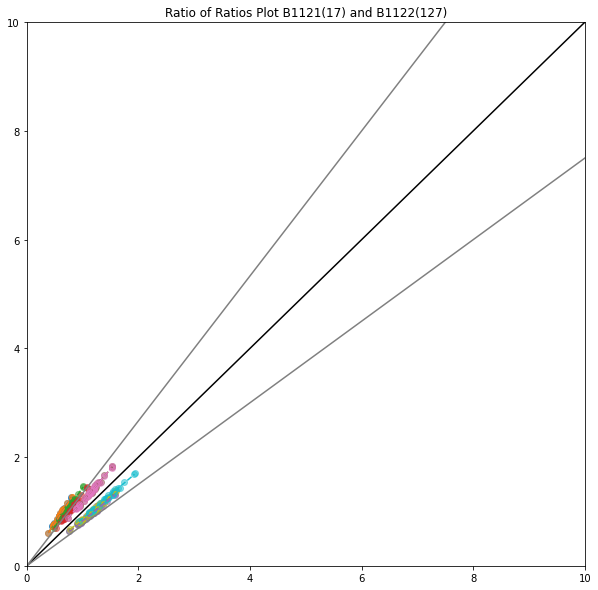

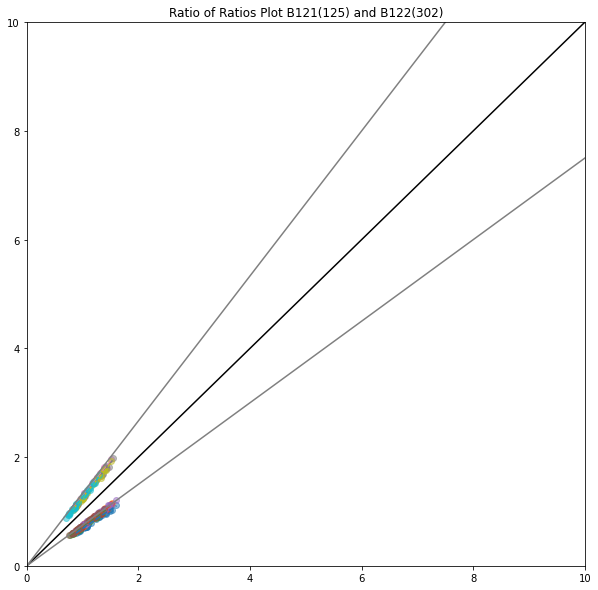

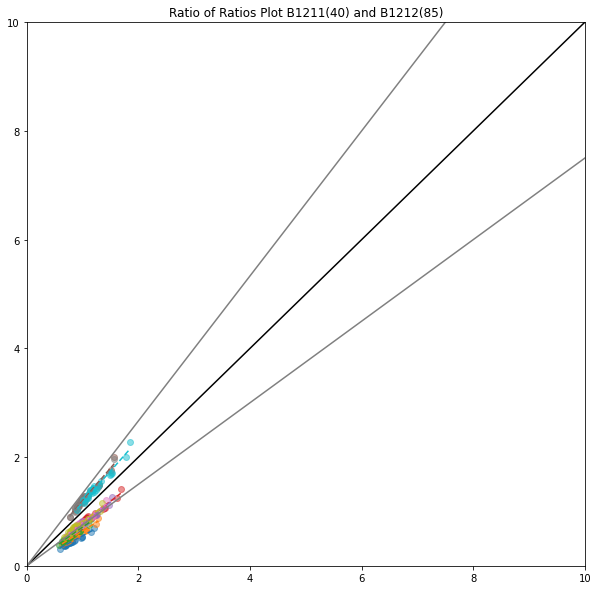

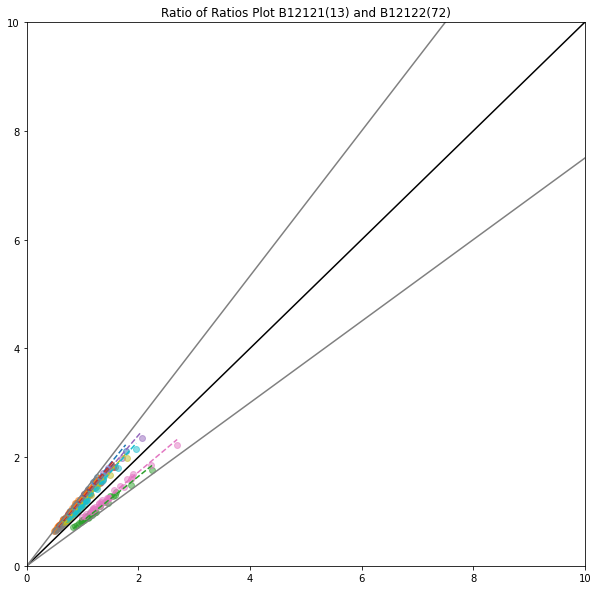

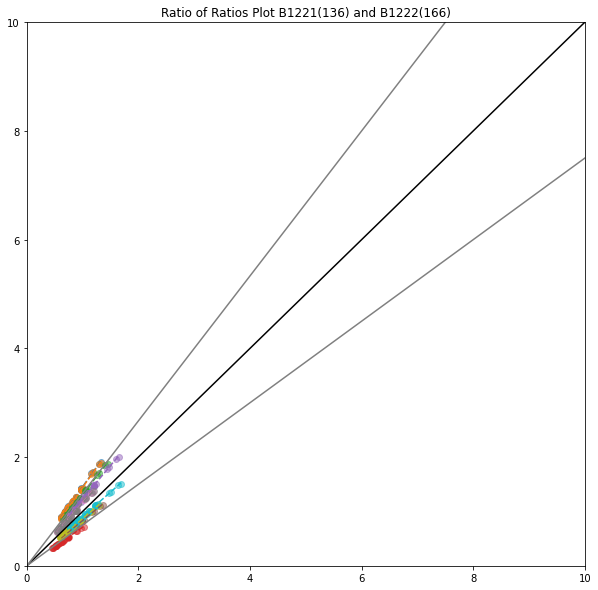

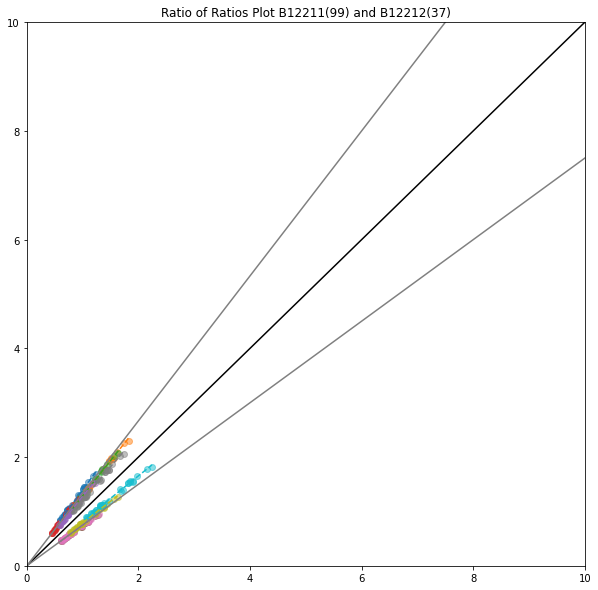

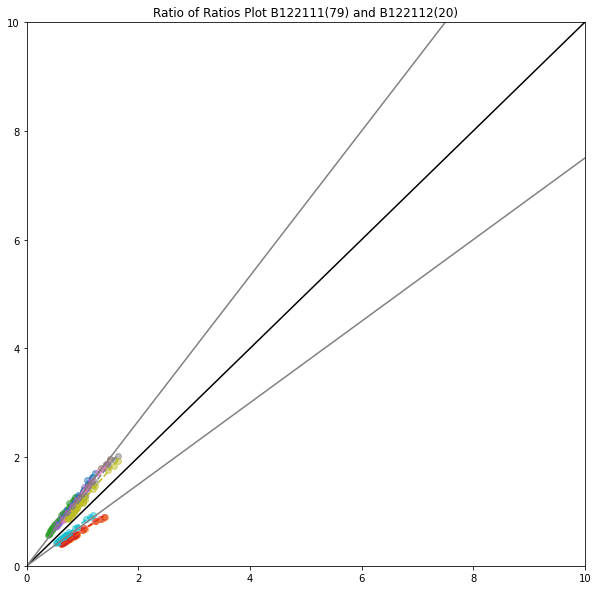

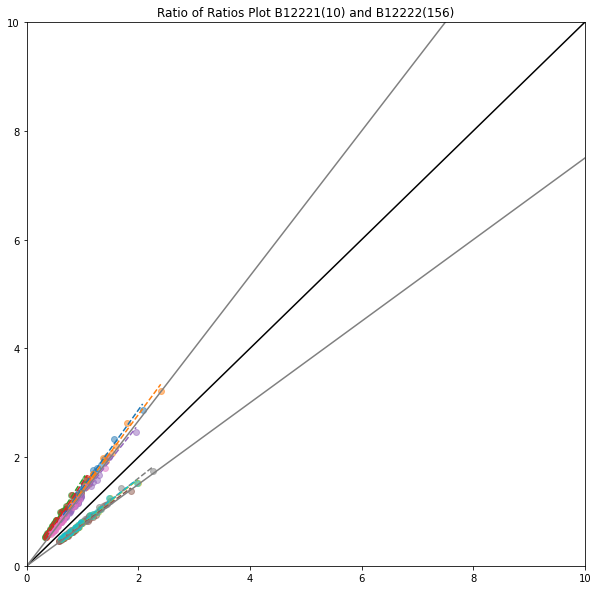

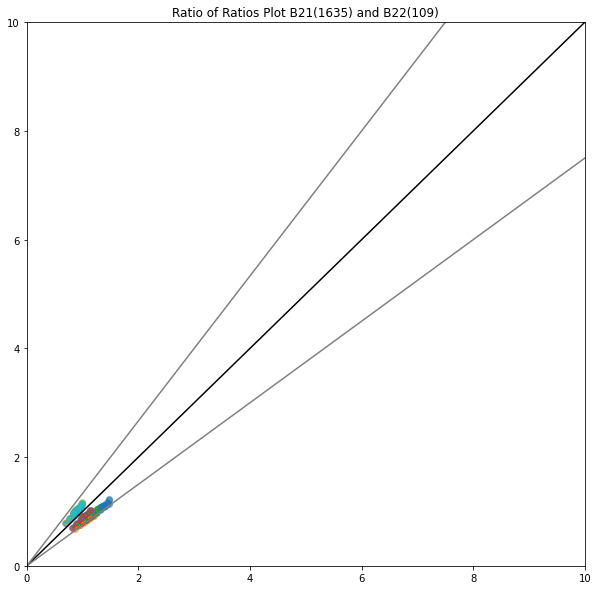

In [8]:
final_populations_B = recursive_em_split(
    all_data_no_WGS, cells, 
    threshold=3/4, max_depth=10, name="B"
)

In [9]:
# 3. Reassign cells based on multinomial parameters
A_dict = reassign_cells(all_data, final_populations_A)
B_dict = reassign_cells(all_data_no_WGS, final_populations_B)



Overlap Matrix (A rows vs B cols):
Pop         B111    B112   B1211   B1212  B12211  B12212   B1222      B2
A1             0       1       1       0       0       0       0    1721
A21          223     144       0       0       0       0       0       2
A2211          0       0       2      78       0       0       1       0
A2212          0       0      52       0       1       0       0       2
A2221          0       0       0       0      11      34       0       0
A22221         0       0       0       0       0       0     130       0
A222221        0       0       1       1      62       3      31       0
A222222        0       0       0       1      27       0       4       0


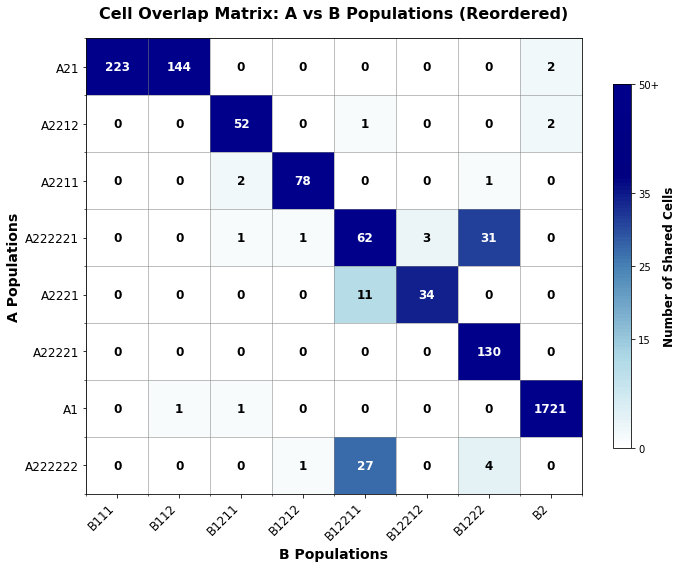

In [10]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict)

In [11]:
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

Computing uniformity data using make_unif_dict...


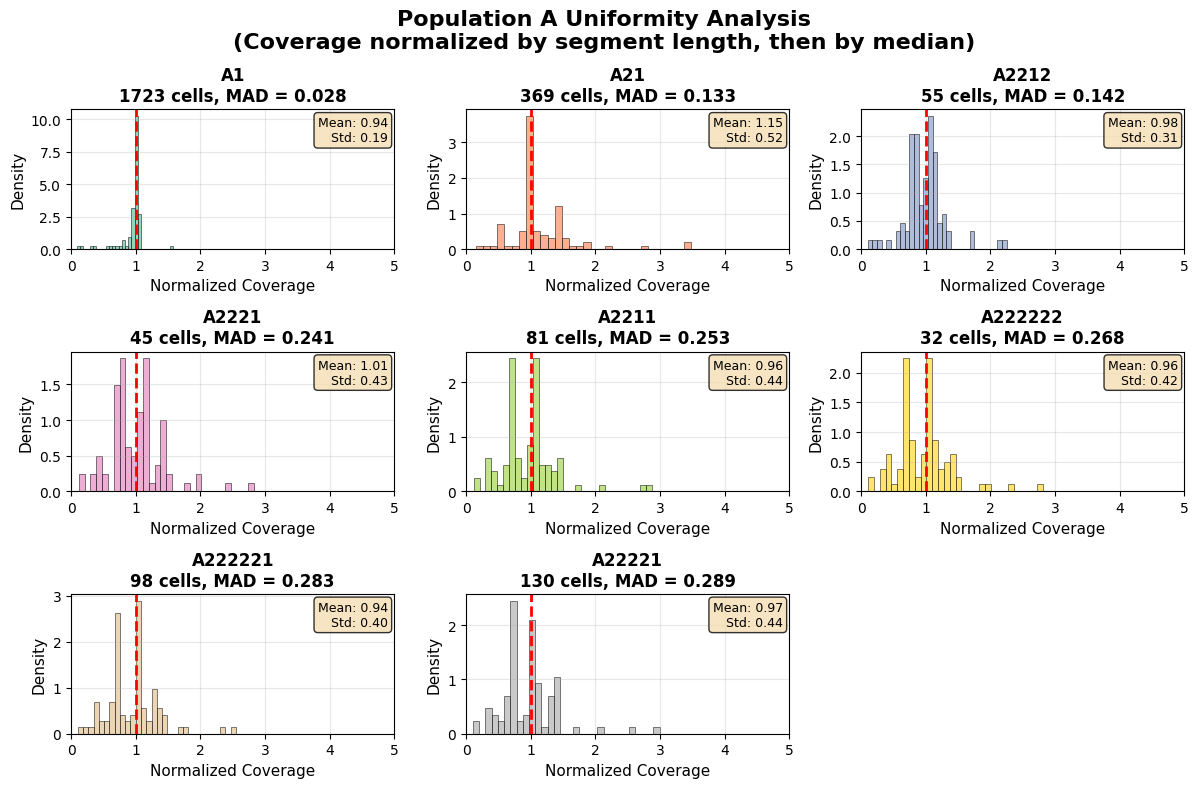


Population A Uniformity Summary:
Population   Cells    MAD      Mean     Std     
------------------------------------------------------------
A1           1723     0.028    0.94     0.19    
A21          369      0.133    1.15     0.52    
A2212        55       0.142    0.98     0.31    
A2221        45       0.241    1.01     0.43    
A2211        81       0.253    0.96     0.44    
A222222      32       0.268    0.96     0.42    
A222221      98       0.283    0.94     0.40    
A22221       130      0.289    0.97     0.44    

Identified normal population: A1 (lowest MAD = 0.028)
Computing uniformity data using make_unif_dict...


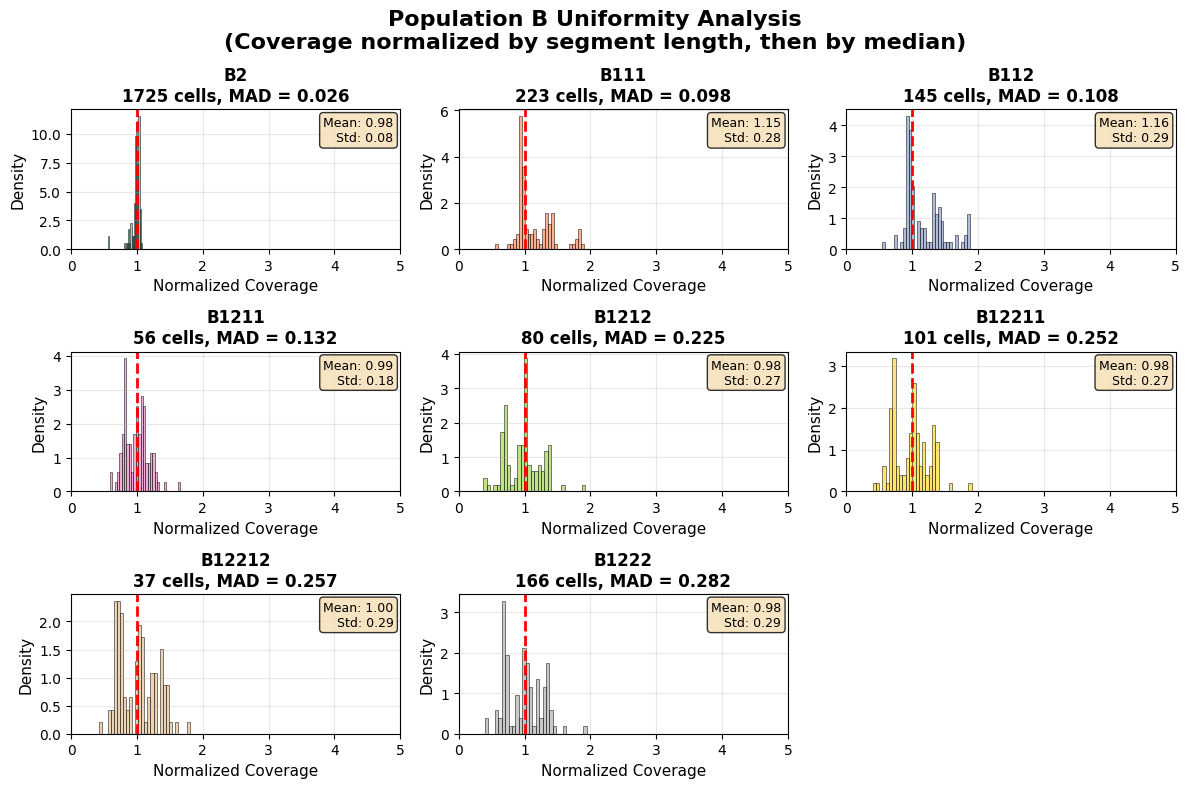


Population B Uniformity Summary:
Population   Cells    MAD      Mean     Std     
------------------------------------------------------------
B2           1725     0.026    0.98     0.08    
B111         223      0.098    1.15     0.28    
B112         145      0.108    1.16     0.29    
B1211        56       0.132    0.99     0.18    
B1212        80       0.225    0.98     0.27    
B12211       101      0.252    0.98     0.27    
B12212       37       0.257    1.00     0.29    
B1222        166      0.282    0.98     0.29    

Identified normal population: B2 (lowest MAD = 0.026)


({'B111': 0     0.939141
  1     1.339548
  2     1.848353
  3     1.797724
  4     0.972923
          ...   
  95    1.345042
  96    1.379893
  97    1.159886
  98    0.909682
  99    0.934289
  Length: 100, dtype: float64, 'B112': 0     0.941199
  1     1.348792
  2     1.871665
  3     1.821765
  4     0.988913
          ...   
  95    1.842458
  96    1.861755
  97    1.238571
  98    0.983442
  99    0.989925
  Length: 100, dtype: float64, 'B1211': 0     0.839252
  1     1.029212
  2     1.247245
  3     1.215076
  4     0.666809
          ...   
  95    1.057330
  96    1.100734
  97    1.027189
  98    0.972140
  99    0.973829
  Length: 100, dtype: float64, 'B1212': 0     0.711679
  1     0.999760
  2     1.375788
  3     1.328587
  4     0.726787
          ...   
  95    1.014510
  96    1.075948
  97    1.164652
  98    0.996195
  99    1.006808
  Length: 100, dtype: float64, 'B12211': 0     0.713248
  1     1.001980
  2     1.396908
  3     1.338337
  4     0.731211
       

In [12]:
plot_uniformity_histograms_nice(all_data, A_dict, data["lengths"], title_prefix="Population A")
plot_uniformity_histograms_nice(all_data_no_WGS, B_dict, data_no_WGS["lengths"], title_prefix="Population B")  

In [13]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)

print("\n=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)

print(f"\nNormal population A: {normal_A}")
print(f"Normal population B: {normal_B}")

=== Population Set A Analysis ===
Normal population identified as: A1

=== Population Set B Analysis ===
Normal population identified as: B2

Normal population A: A1
Normal population B: B2


In [14]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  A1_ratio  A21_ratio  A2211_ratio  \
0  chr1          0   45387037           0       1.0   0.962910     0.889608   
1  chr1   45972336  119478274           1       1.0   1.822015     1.677123   
2  chr1  120035598  175362842           2       1.0   1.461517     2.310204   
3  chr1  175900450  182029442           3       1.0   1.163559     1.671844   
4  chr1  182578512  248389233           4       1.0   0.953874     0.863291   

   A2212_ratio  A2221_ratio  A22221_ratio  A222221_ratio  A222222_ratio  
0     1.154319     0.895589      0.986838       0.961246       0.899004  
1     1.656995     1.705711      1.786567       1.750204       1.756304  
2     2.171750     1.957003      2.440350       2.362939       2.308747  
3     1.717761     2.275755      1.771564       1.728365       1.588595  
4     1.116804     1.239868      0.890618       0.896658       0.799557  

Population B ratios:
  chrom      start        end  segment

In [15]:
# Perform ploidy optimization for each population in set A (excluding normal)
print("=== Ploidy Optimization for Population Set A ===")

# Get all population ratio columns (excluding normal population)
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results = compute_optimal_ploidy_and_profile(
        ratios_A, 
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

=== Ploidy Optimization for Population Set A ===
Normal population: A1
Populations to optimize: ['A21', 'A2211', 'A2212', 'A2221', 'A22221', 'A222221', 'A222222']

Optimizing ploidy for population: A21

Optimal Results for A21:
Optimal multiplier (m): 2.100
Minimum cost: 5.55e+07
Average copy number: 2.48
Optimal multiplier for A21: 2.100

Optimizing ploidy for population: A2211

Optimal Results for A2211:
Optimal multiplier (m): 2.400
Minimum cost: 7.49e+07
Average copy number: 2.96
Optimal multiplier for A2211: 2.400

Optimizing ploidy for population: A2212

Optimal Results for A2212:
Optimal multiplier (m): 3.600
Minimum cost: 1.59e+08
Average copy number: 4.89
Optimal multiplier for A2212: 3.600

Optimizing ploidy for population: A2221

Optimal Results for A2221:
Optimal multiplier (m): 2.300
Minimum cost: 9.72e+07
Average copy number: 2.92
Optimal multiplier for A2221: 2.300

Optimizing ploidy for population: A22221

Optimal Results for A22221:
Optimal multiplier (m): 2.300
Minimu

In [16]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: A21

Optimal Results for A21:
Optimal multiplier (m): 2.100
Minimum cost: 5.55e+07
Average copy number: 2.48
Found 4 local minima
Optimal multiplier for A21: 2.100
Found 4 local minima: ['2.10', '4.30', '5.10', '3.00']

Optimizing ploidy for population: A2211

Optimal Results for A2211:
Optimal multiplier (m): 2.400
Minimum cost: 7.49e+07
Average copy number: 2.96
Found 6 local minima
Optimal multiplier for A2211: 2.400
Found 6 local minima: ['2.40', '4.70', '5.50', '3.10', '3.70']

Optimizing ploidy for population: A2212

Optimal Results for A2212:
Optimal multiplier (m): 3.600
Minimum cost: 1.59e+08
Average copy number: 4.89
Found 6 local minima
Optimal multiplier for A2212: 3.600
Found 6 local minima: ['3.60', '1.90', '5.40', '2.80', '4.30']

Optimizing ploidy for population: A2221

Optimal Results for A2221:
Optimal multiplier (m): 2.300
Minimum cost: 9.72e+07
Average copy number: 2.92
Found 6 local minima
Optimal multiplier for A2221: 2.300
Found


Plotting results for population: A21


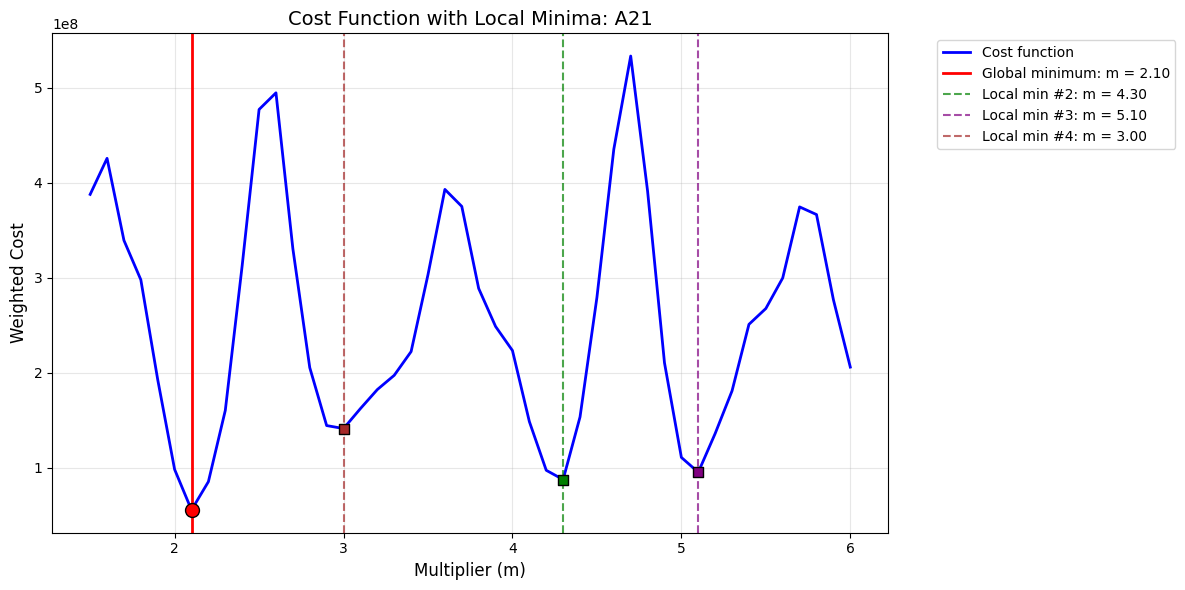


Local Minima Summary for A21:
--------------------------------------------------
#1: m = 2.10, cost = 5.55e+07 (GLOBAL)
#2: m = 4.30, cost = 8.76e+07
#3: m = 5.10, cost = 9.53e+07
#4: m = 3.00, cost = 1.41e+08


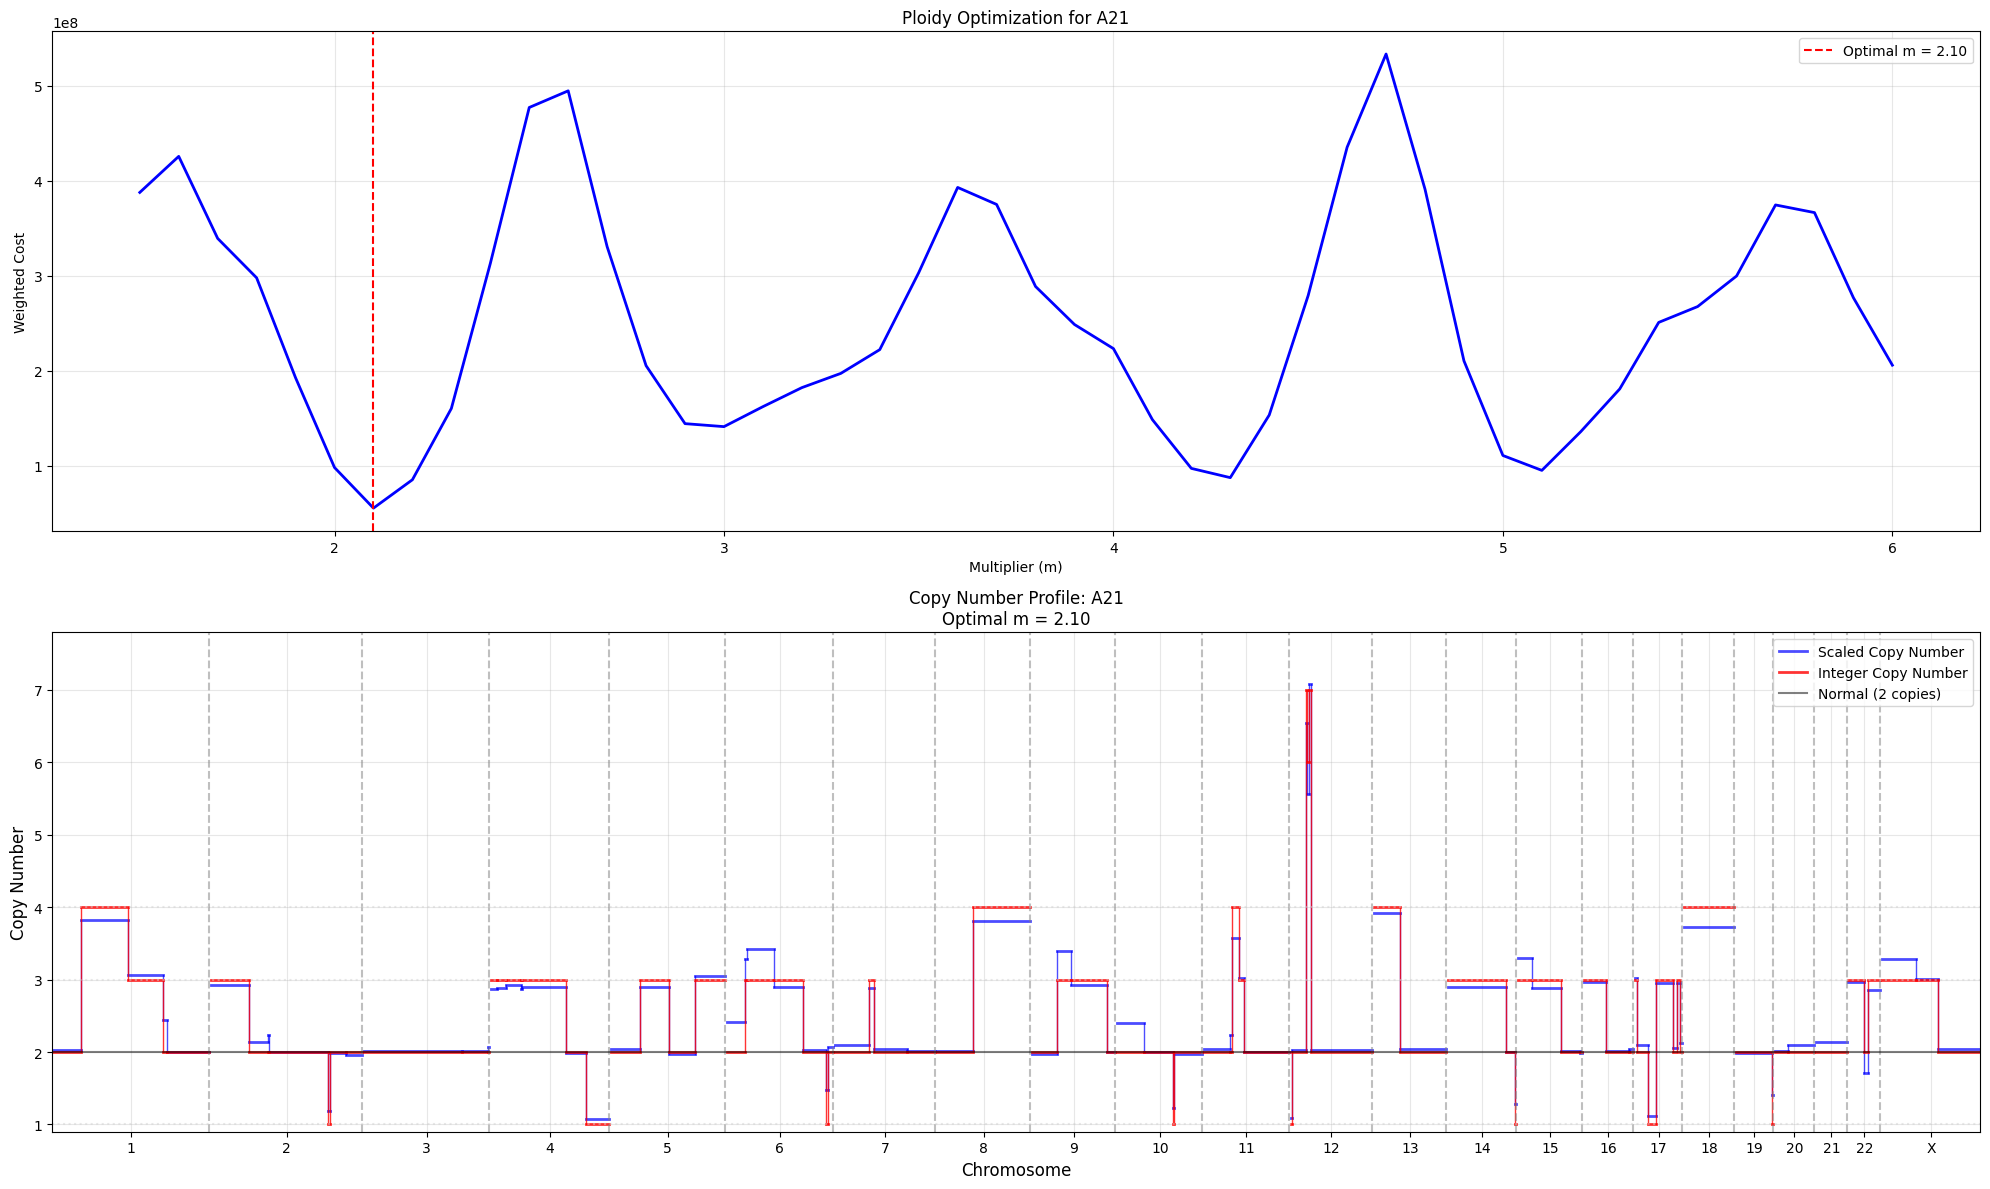

Completed plots for A21

Plotting results for population: A2211


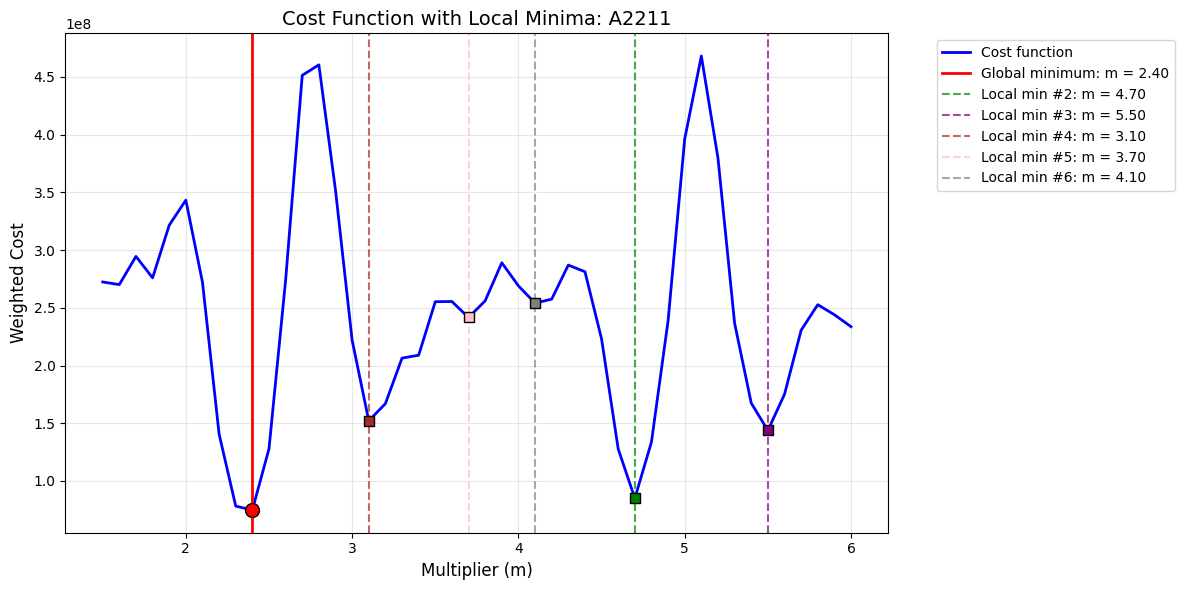


Local Minima Summary for A2211:
--------------------------------------------------
#1: m = 2.40, cost = 7.49e+07 (GLOBAL)
#2: m = 4.70, cost = 8.50e+07
#3: m = 5.50, cost = 1.44e+08
#4: m = 3.10, cost = 1.52e+08
#5: m = 3.70, cost = 2.42e+08
#6: m = 4.10, cost = 2.54e+08


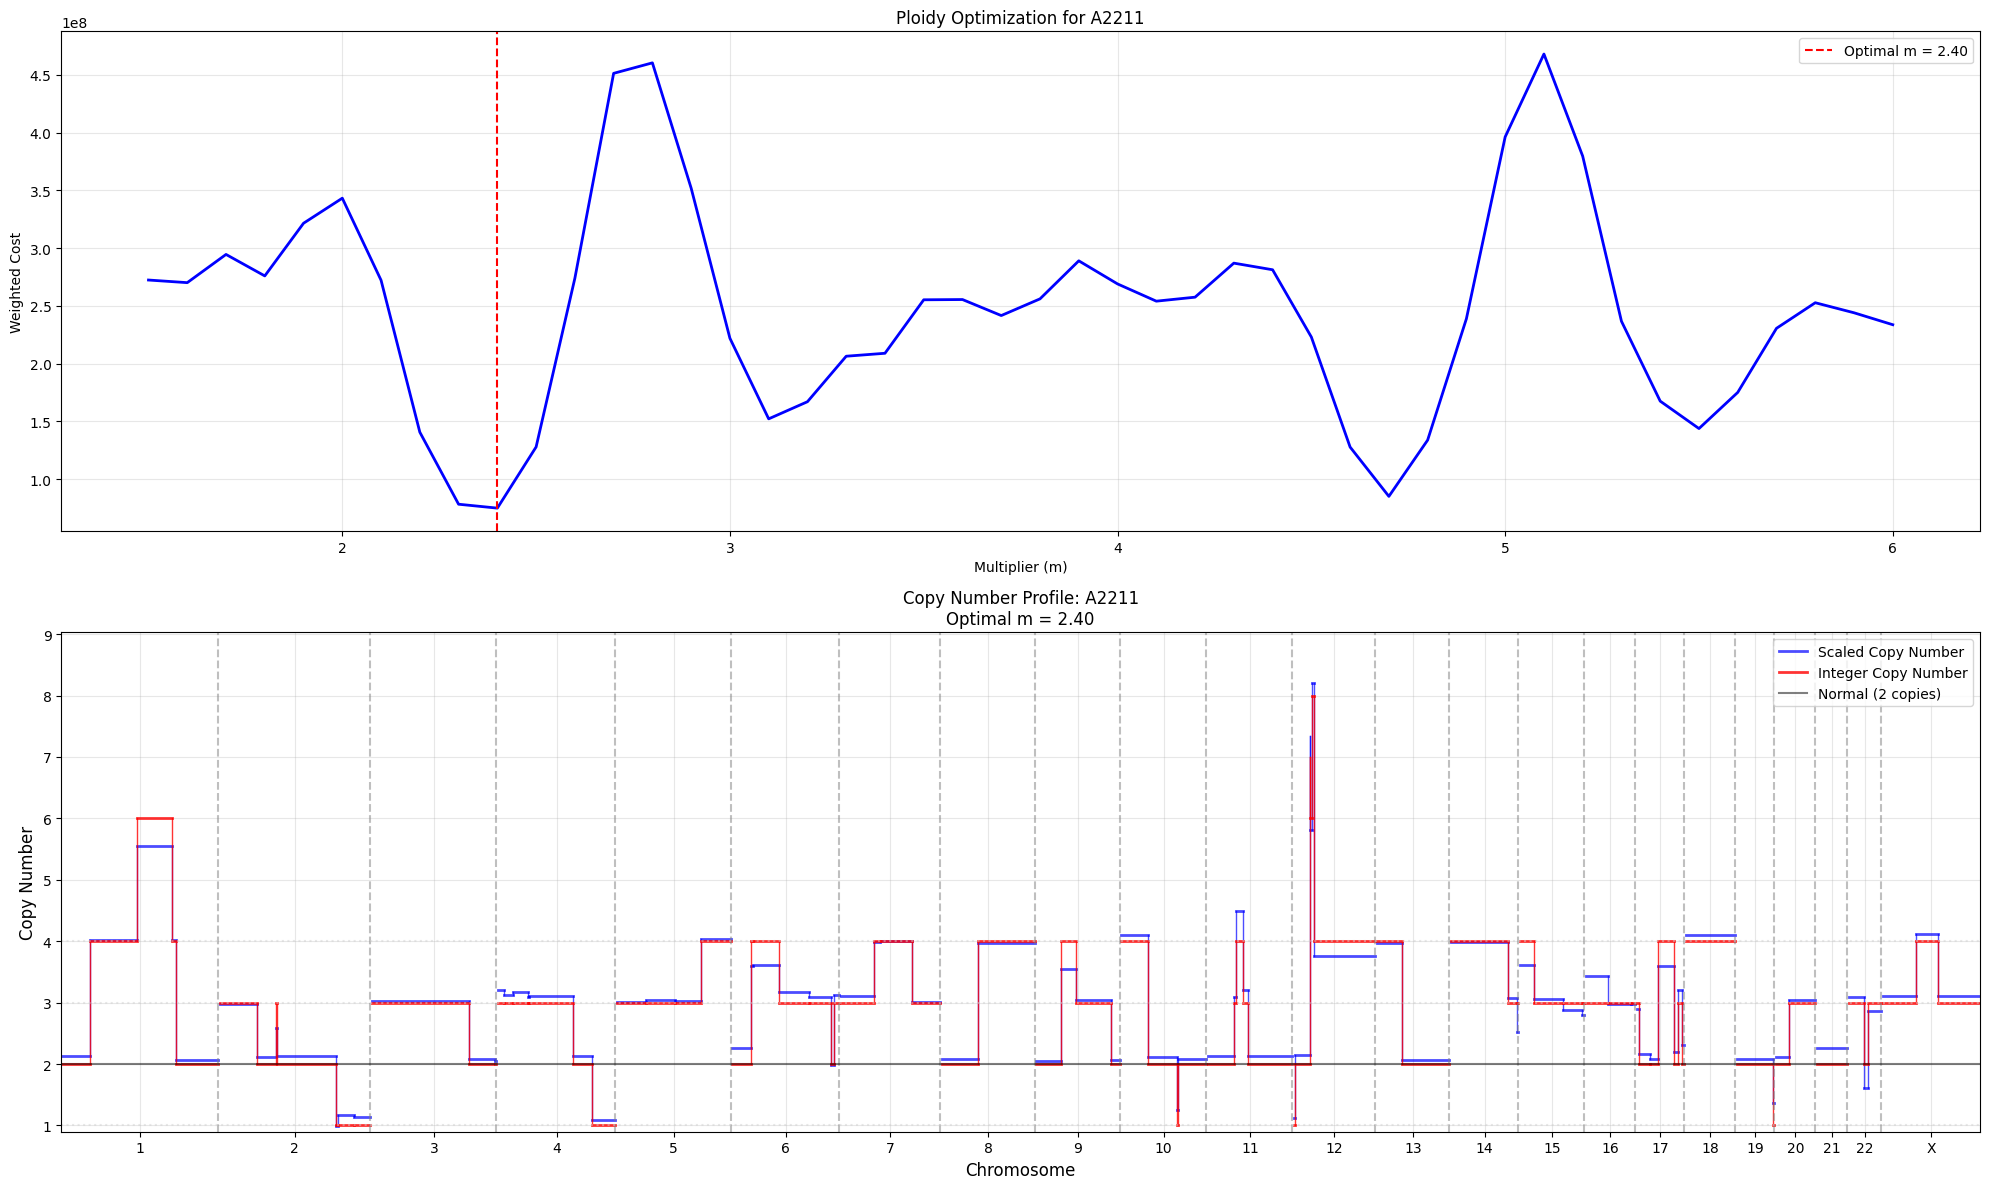

Completed plots for A2211

Plotting results for population: A2212


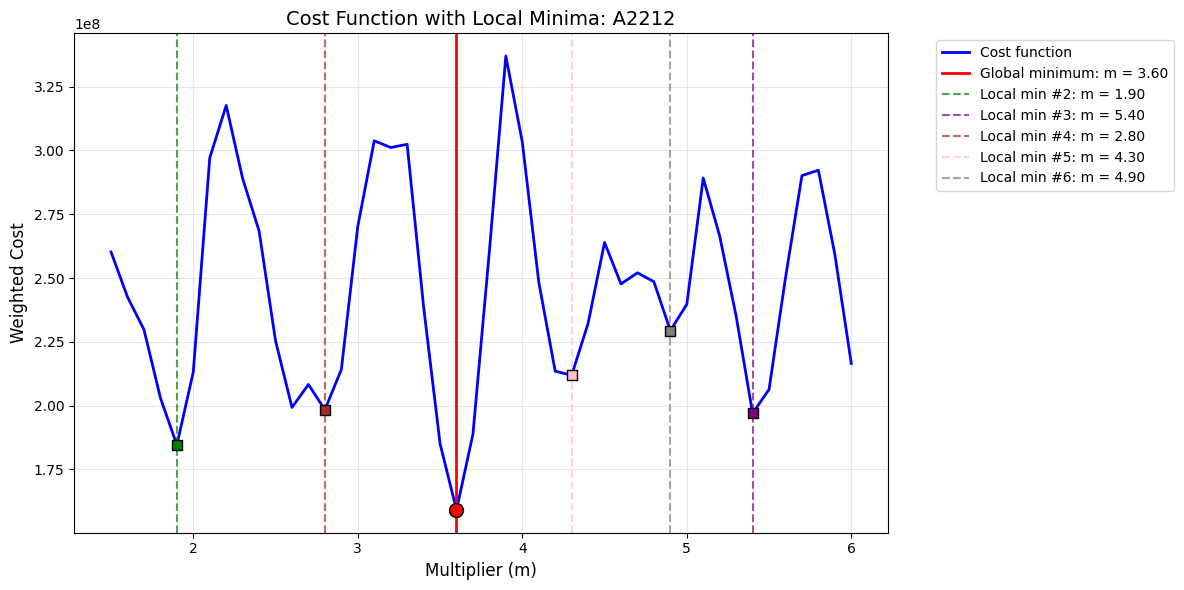


Local Minima Summary for A2212:
--------------------------------------------------
#1: m = 3.60, cost = 1.59e+08 (GLOBAL)
#2: m = 1.90, cost = 1.85e+08
#3: m = 5.40, cost = 1.97e+08
#4: m = 2.80, cost = 1.98e+08
#5: m = 4.30, cost = 2.12e+08
#6: m = 4.90, cost = 2.29e+08


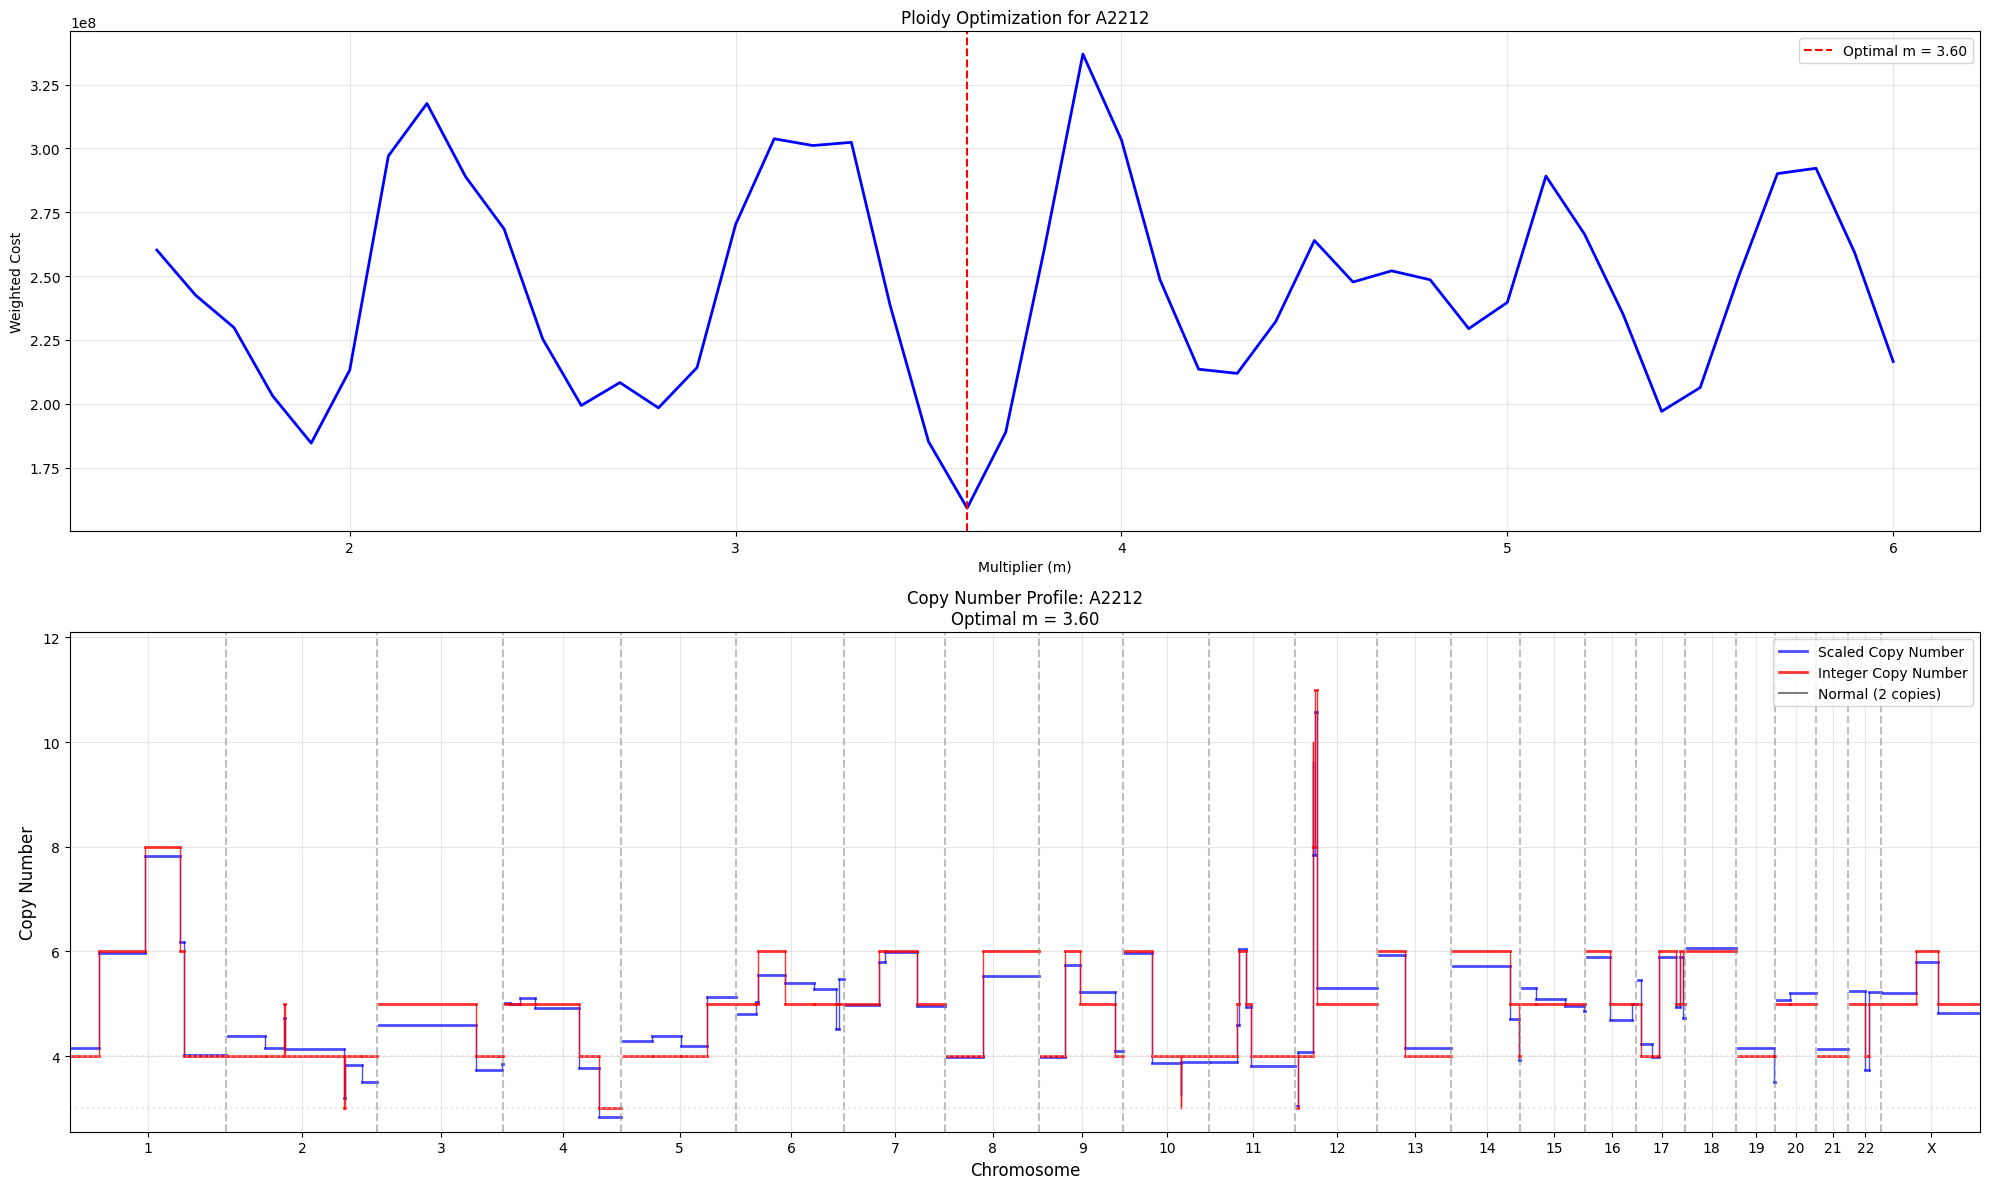

Completed plots for A2212

Plotting results for population: A2221


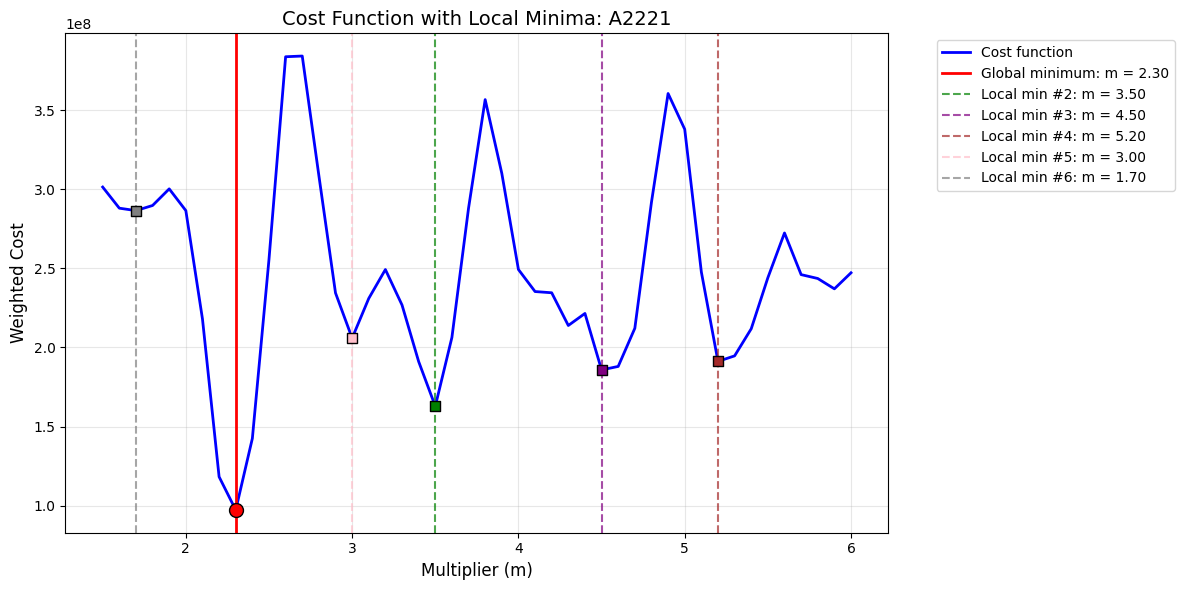


Local Minima Summary for A2221:
--------------------------------------------------
#1: m = 2.30, cost = 9.72e+07 (GLOBAL)
#2: m = 3.50, cost = 1.63e+08
#3: m = 4.50, cost = 1.86e+08
#4: m = 5.20, cost = 1.91e+08
#5: m = 3.00, cost = 2.06e+08
#6: m = 1.70, cost = 2.87e+08


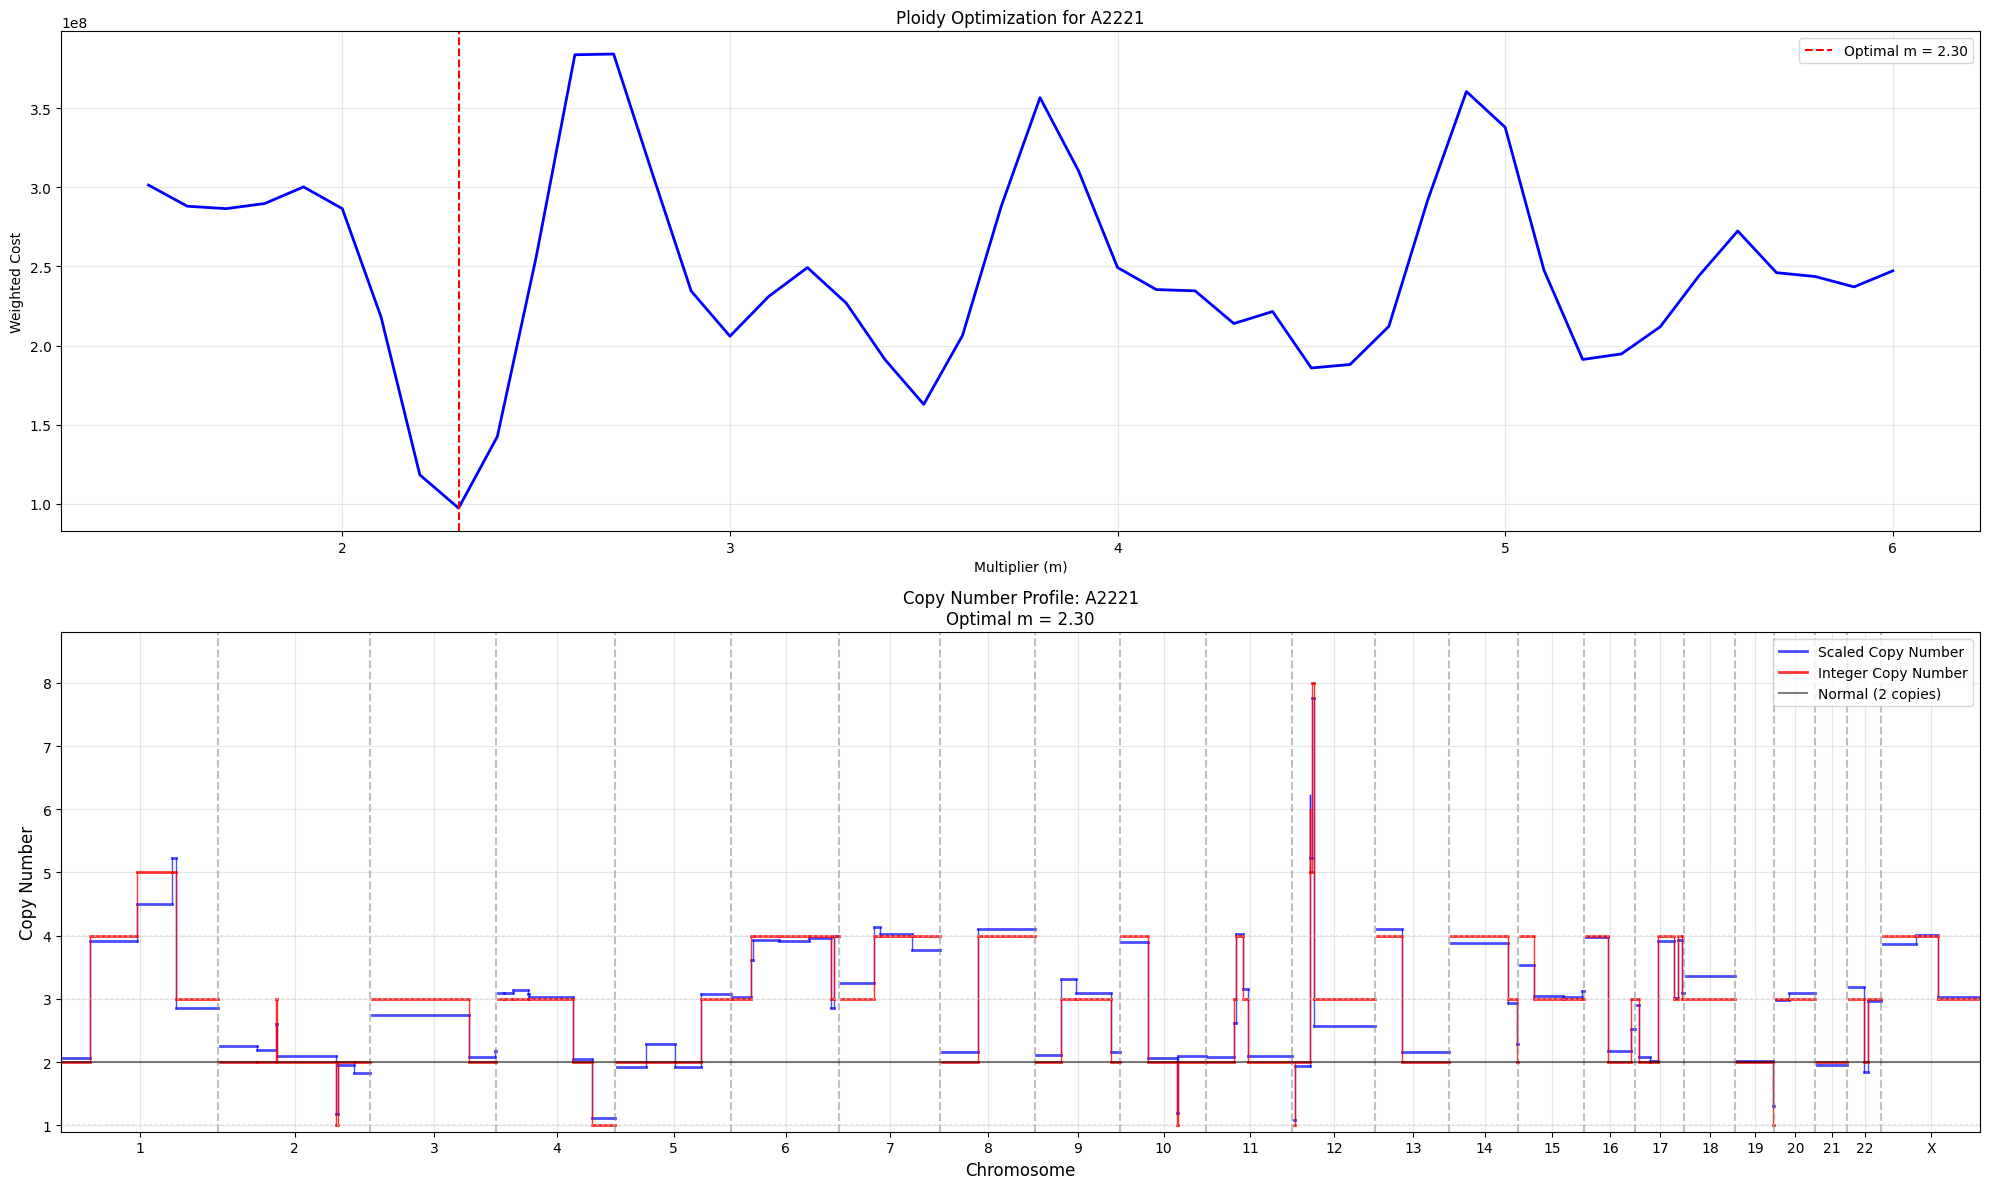

Completed plots for A2221

Plotting results for population: A22221


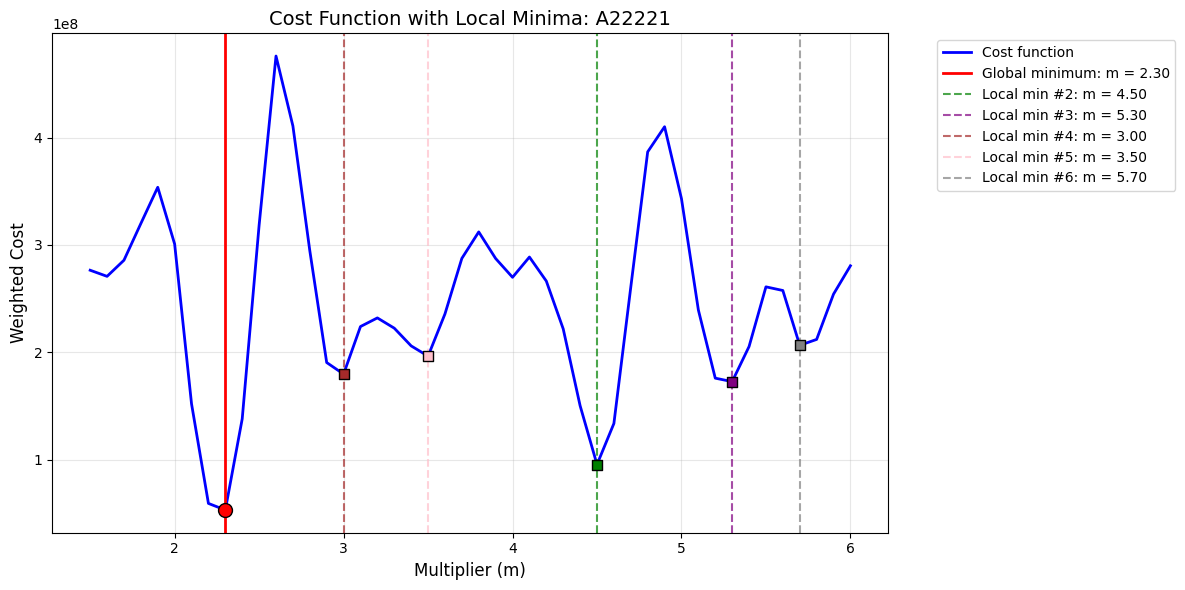


Local Minima Summary for A22221:
--------------------------------------------------
#1: m = 2.30, cost = 5.30e+07 (GLOBAL)
#2: m = 4.50, cost = 9.54e+07
#3: m = 5.30, cost = 1.73e+08
#4: m = 3.00, cost = 1.80e+08
#5: m = 3.50, cost = 1.96e+08
#6: m = 5.70, cost = 2.06e+08


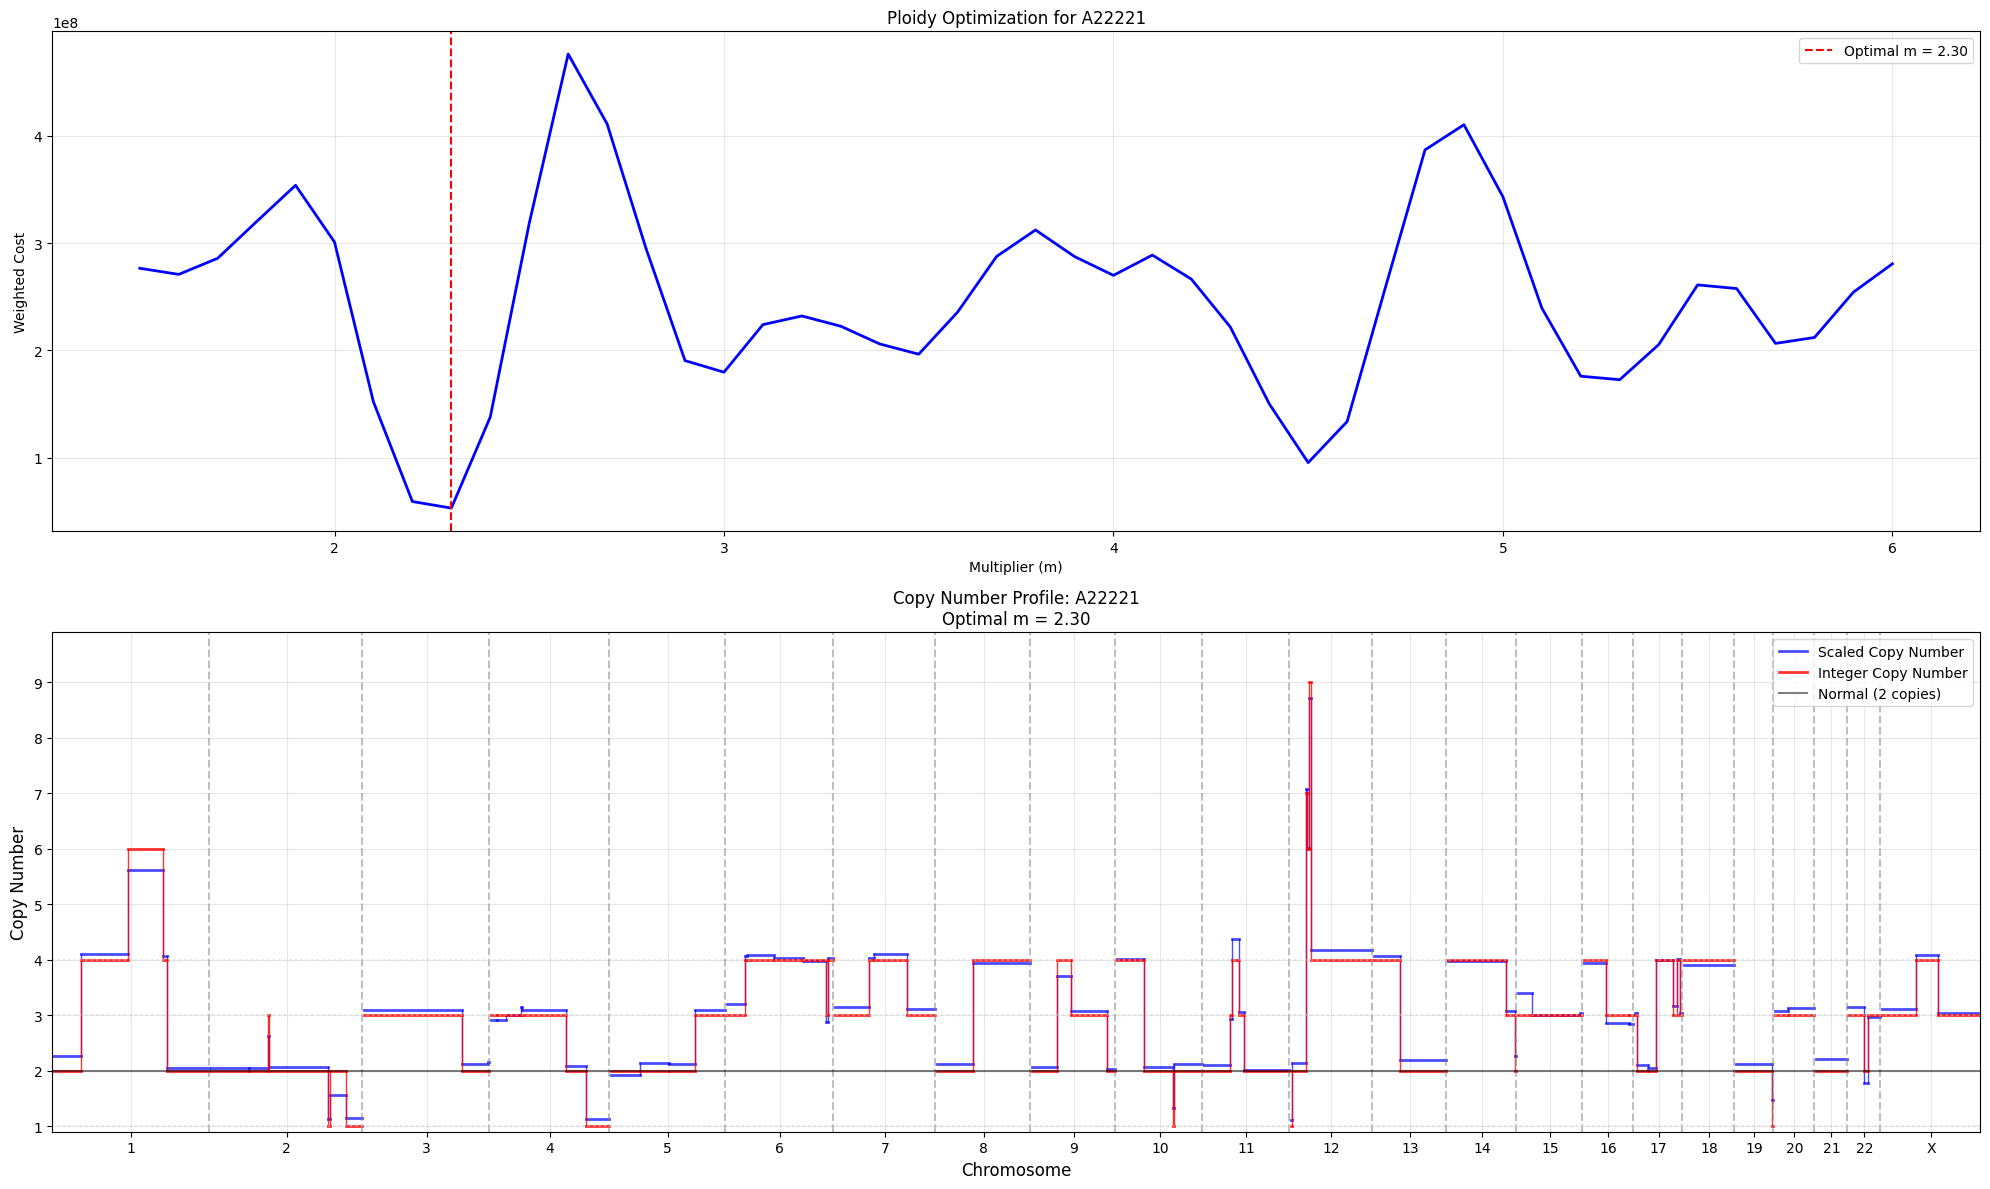

Completed plots for A22221

Plotting results for population: A222221


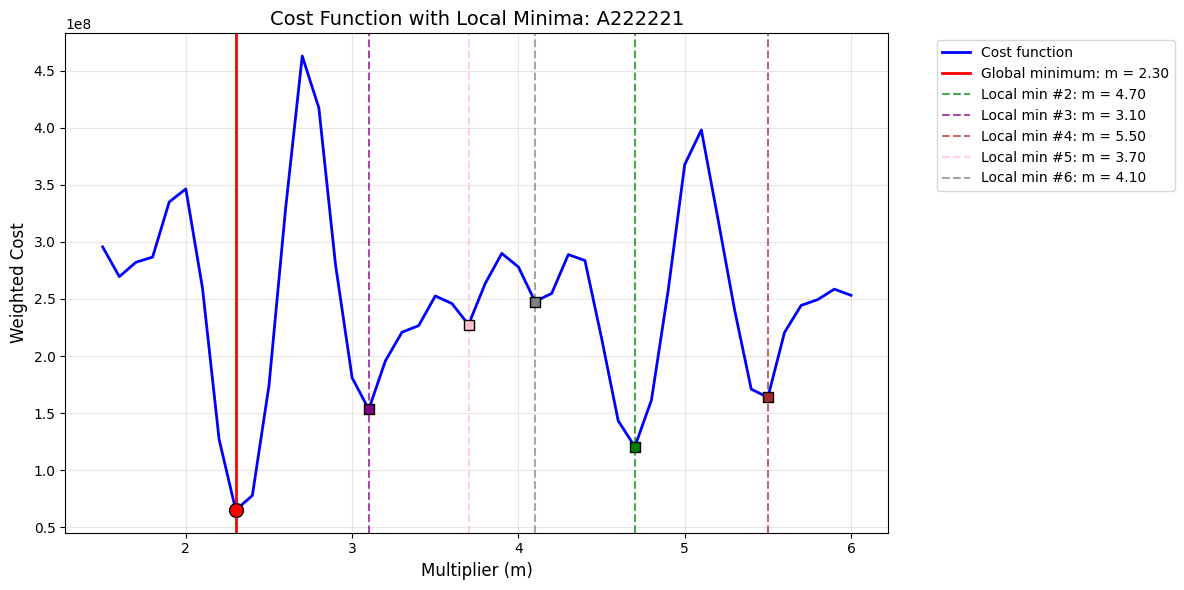


Local Minima Summary for A222221:
--------------------------------------------------
#1: m = 2.30, cost = 6.51e+07 (GLOBAL)
#2: m = 4.70, cost = 1.21e+08
#3: m = 3.10, cost = 1.53e+08
#4: m = 5.50, cost = 1.64e+08
#5: m = 3.70, cost = 2.27e+08
#6: m = 4.10, cost = 2.48e+08


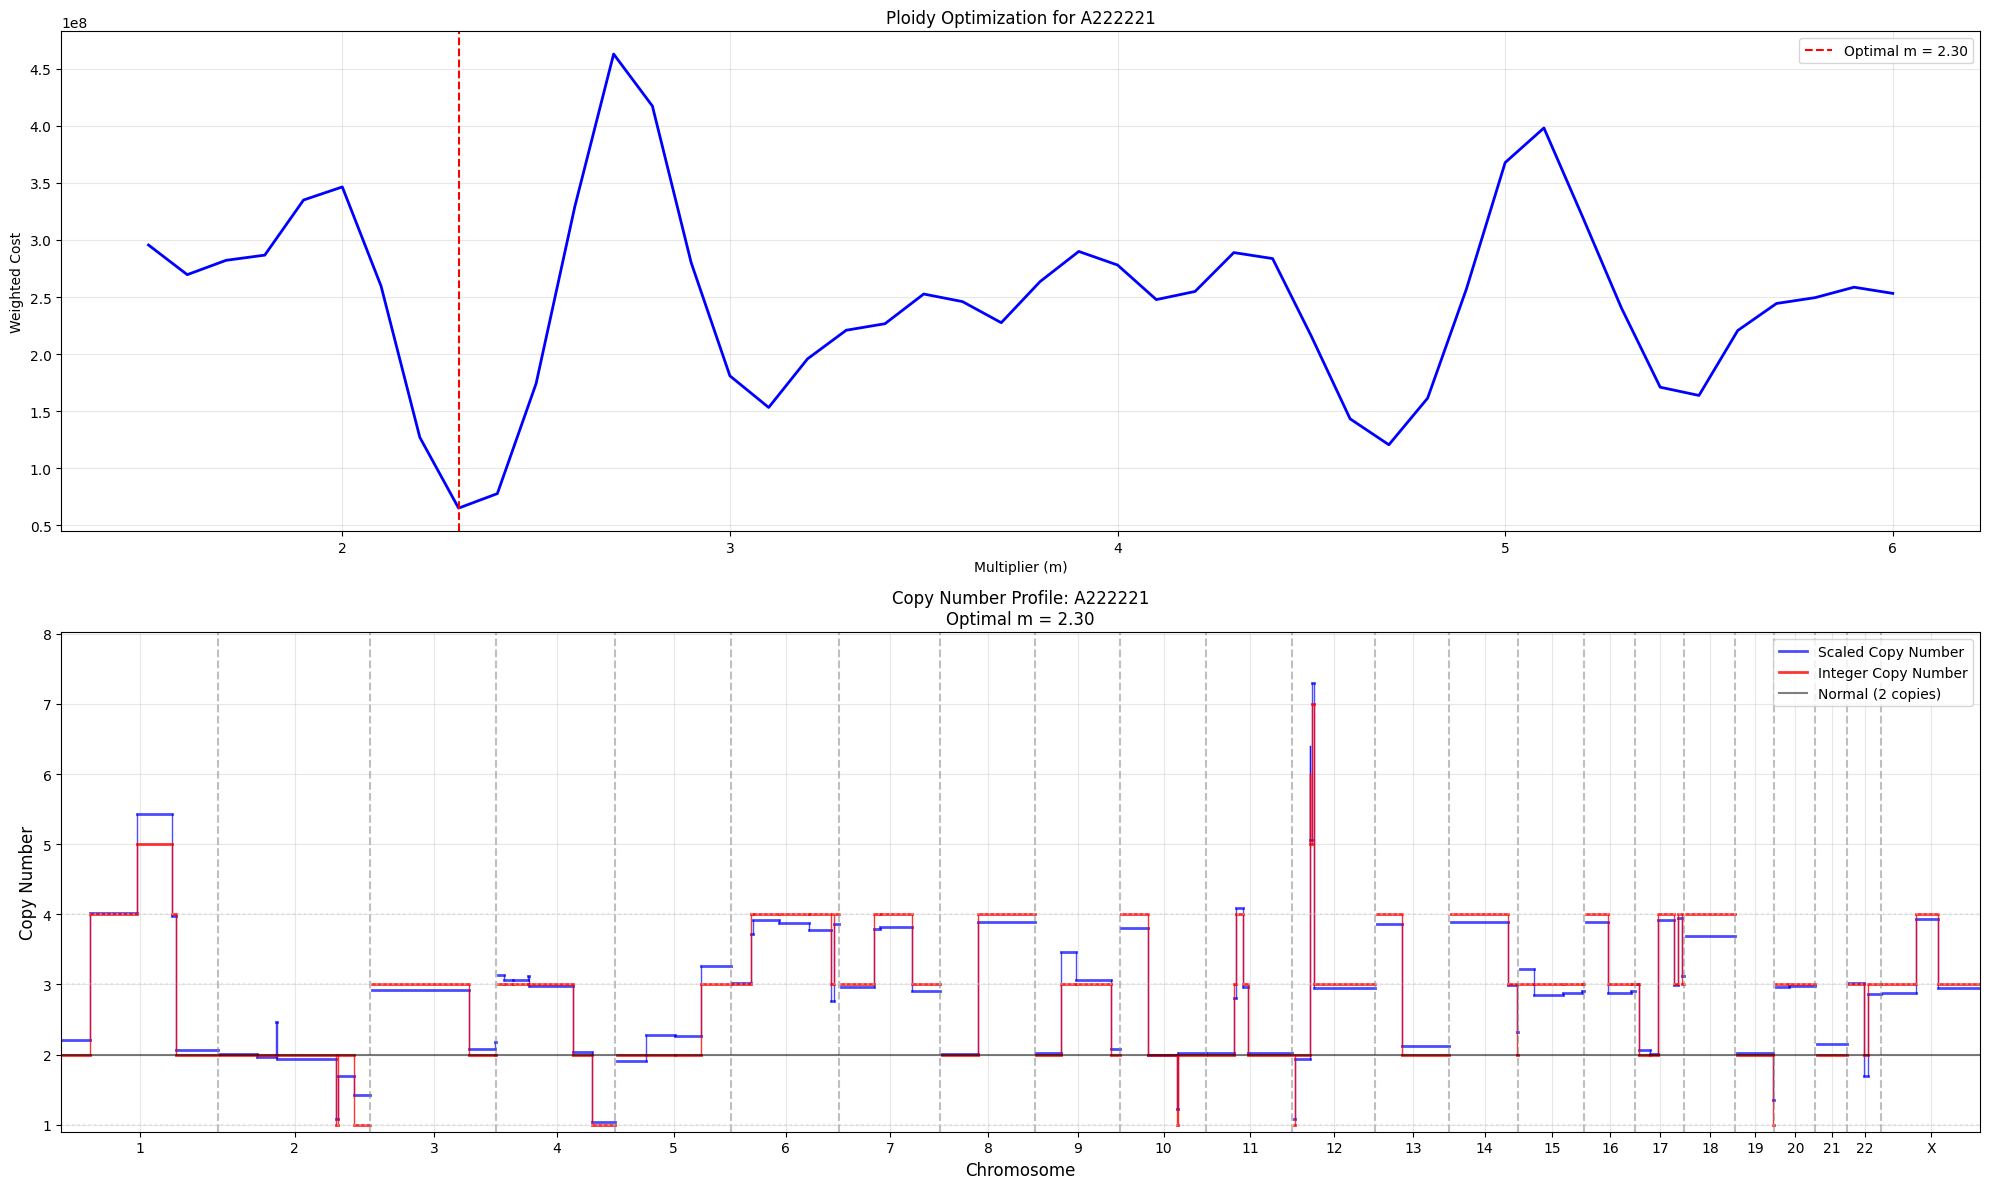

Completed plots for A222221

Plotting results for population: A222222


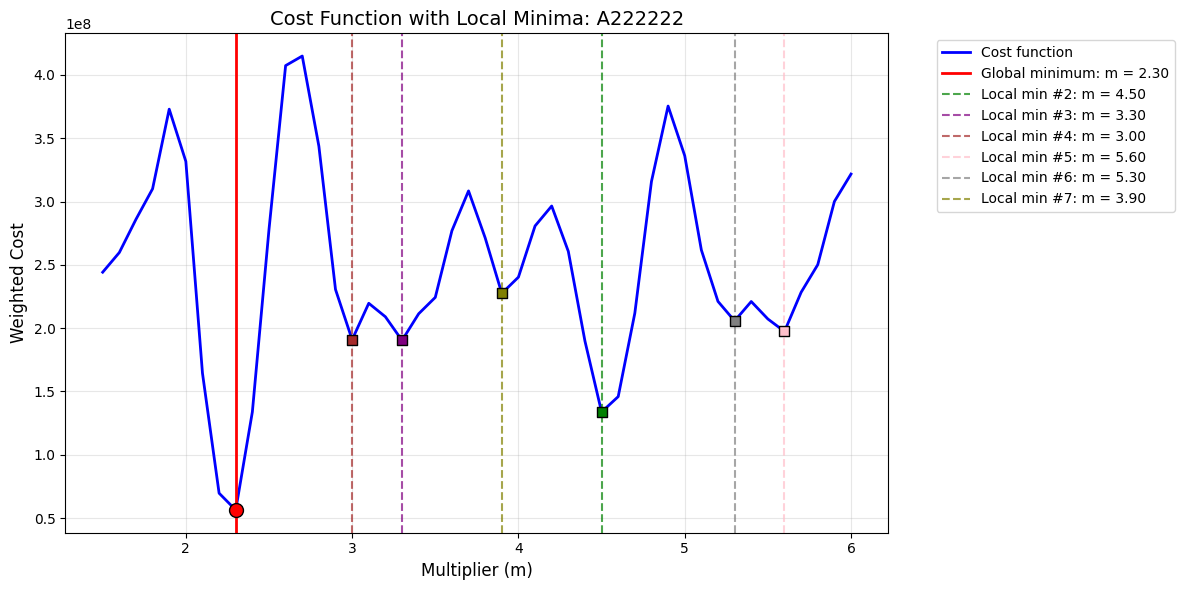


Local Minima Summary for A222222:
--------------------------------------------------
#1: m = 2.30, cost = 5.64e+07 (GLOBAL)
#2: m = 4.50, cost = 1.34e+08
#3: m = 3.30, cost = 1.90e+08
#4: m = 3.00, cost = 1.91e+08
#5: m = 5.60, cost = 1.97e+08
#6: m = 5.30, cost = 2.06e+08
#7: m = 3.90, cost = 2.27e+08


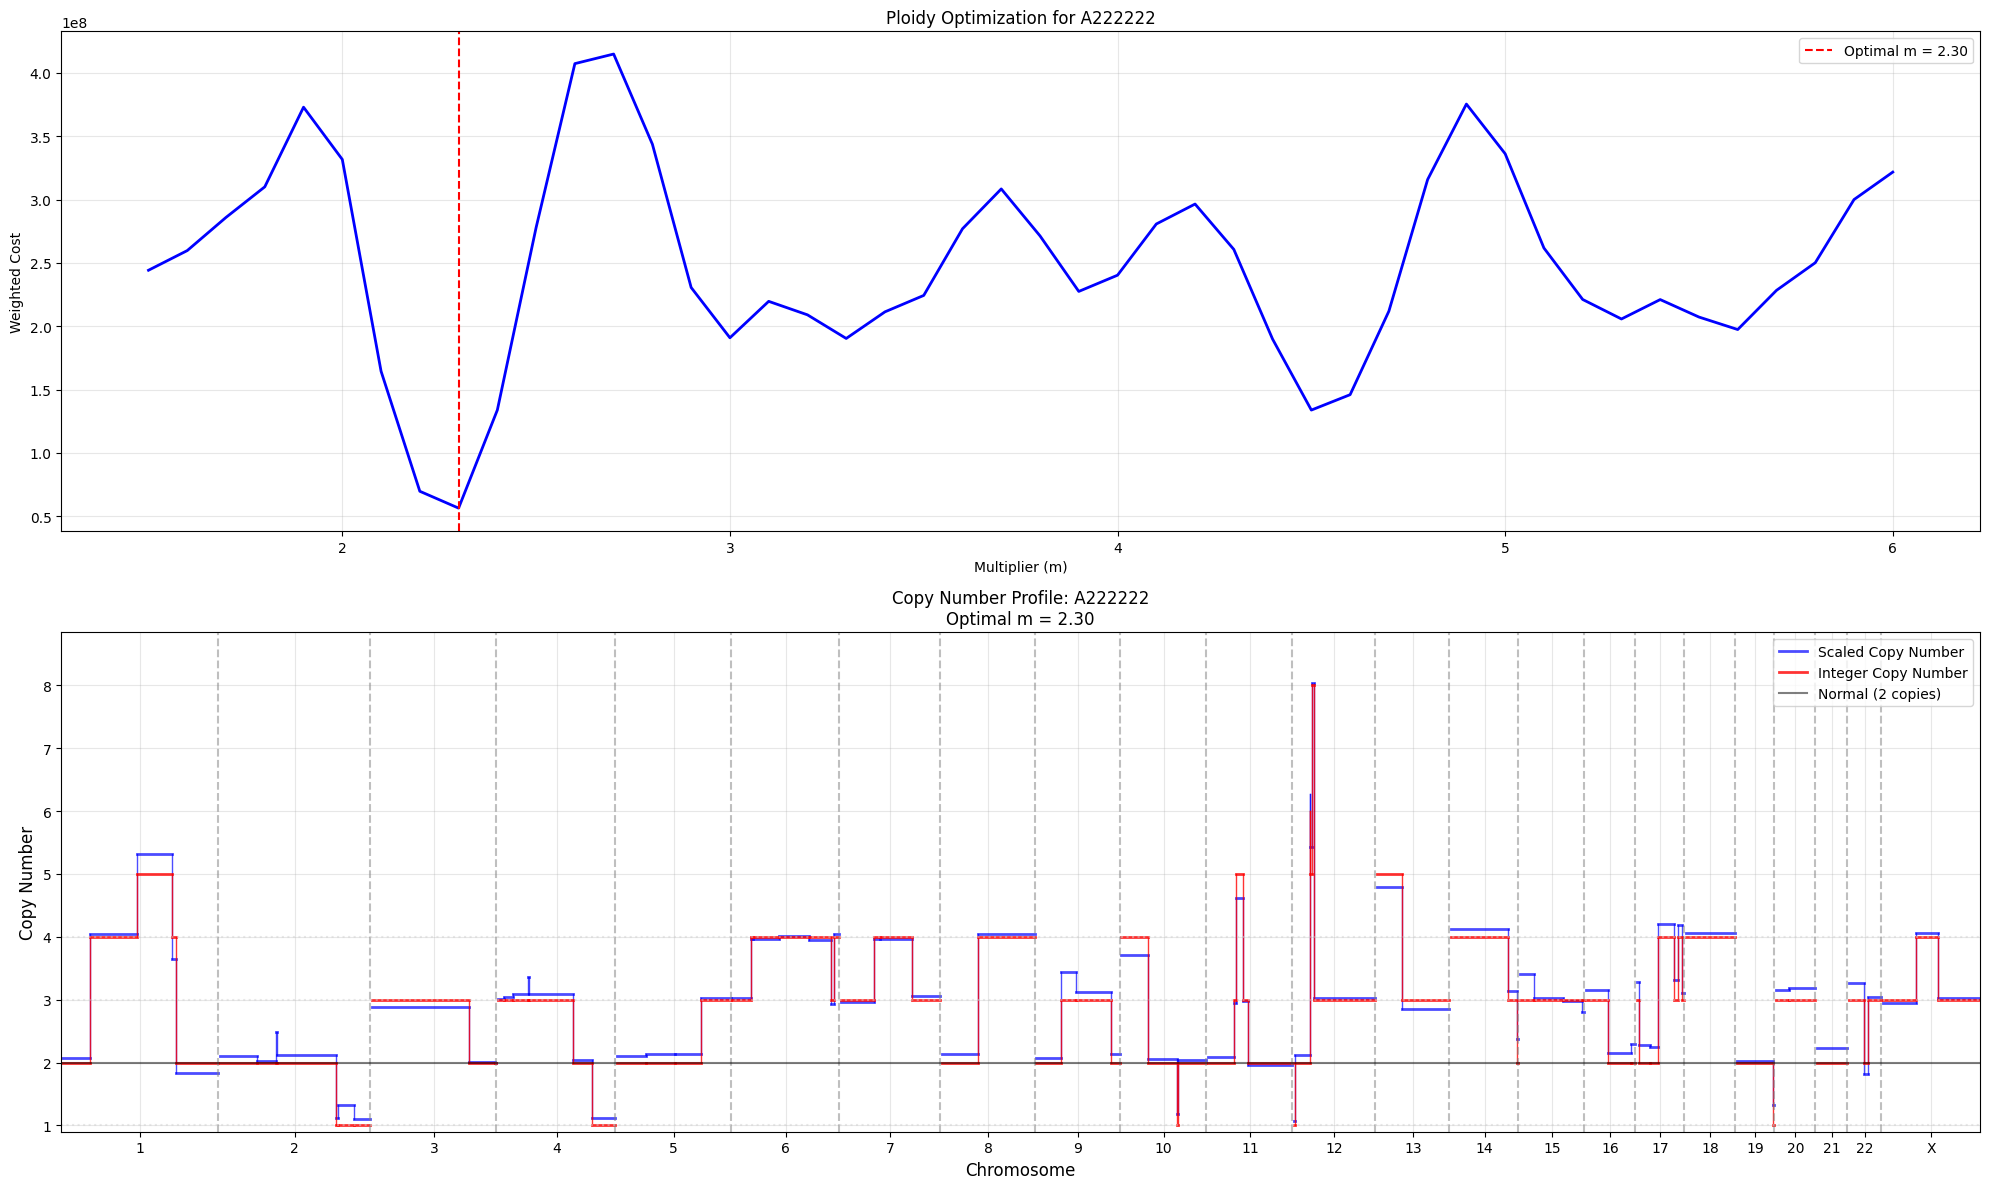

Completed plots for A222222


In [17]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [18]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = "../data/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/t57/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (8605992, 6)
hap_count_df ready for analysis!


In [19]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))


Creating ploidy comparison for population: A21


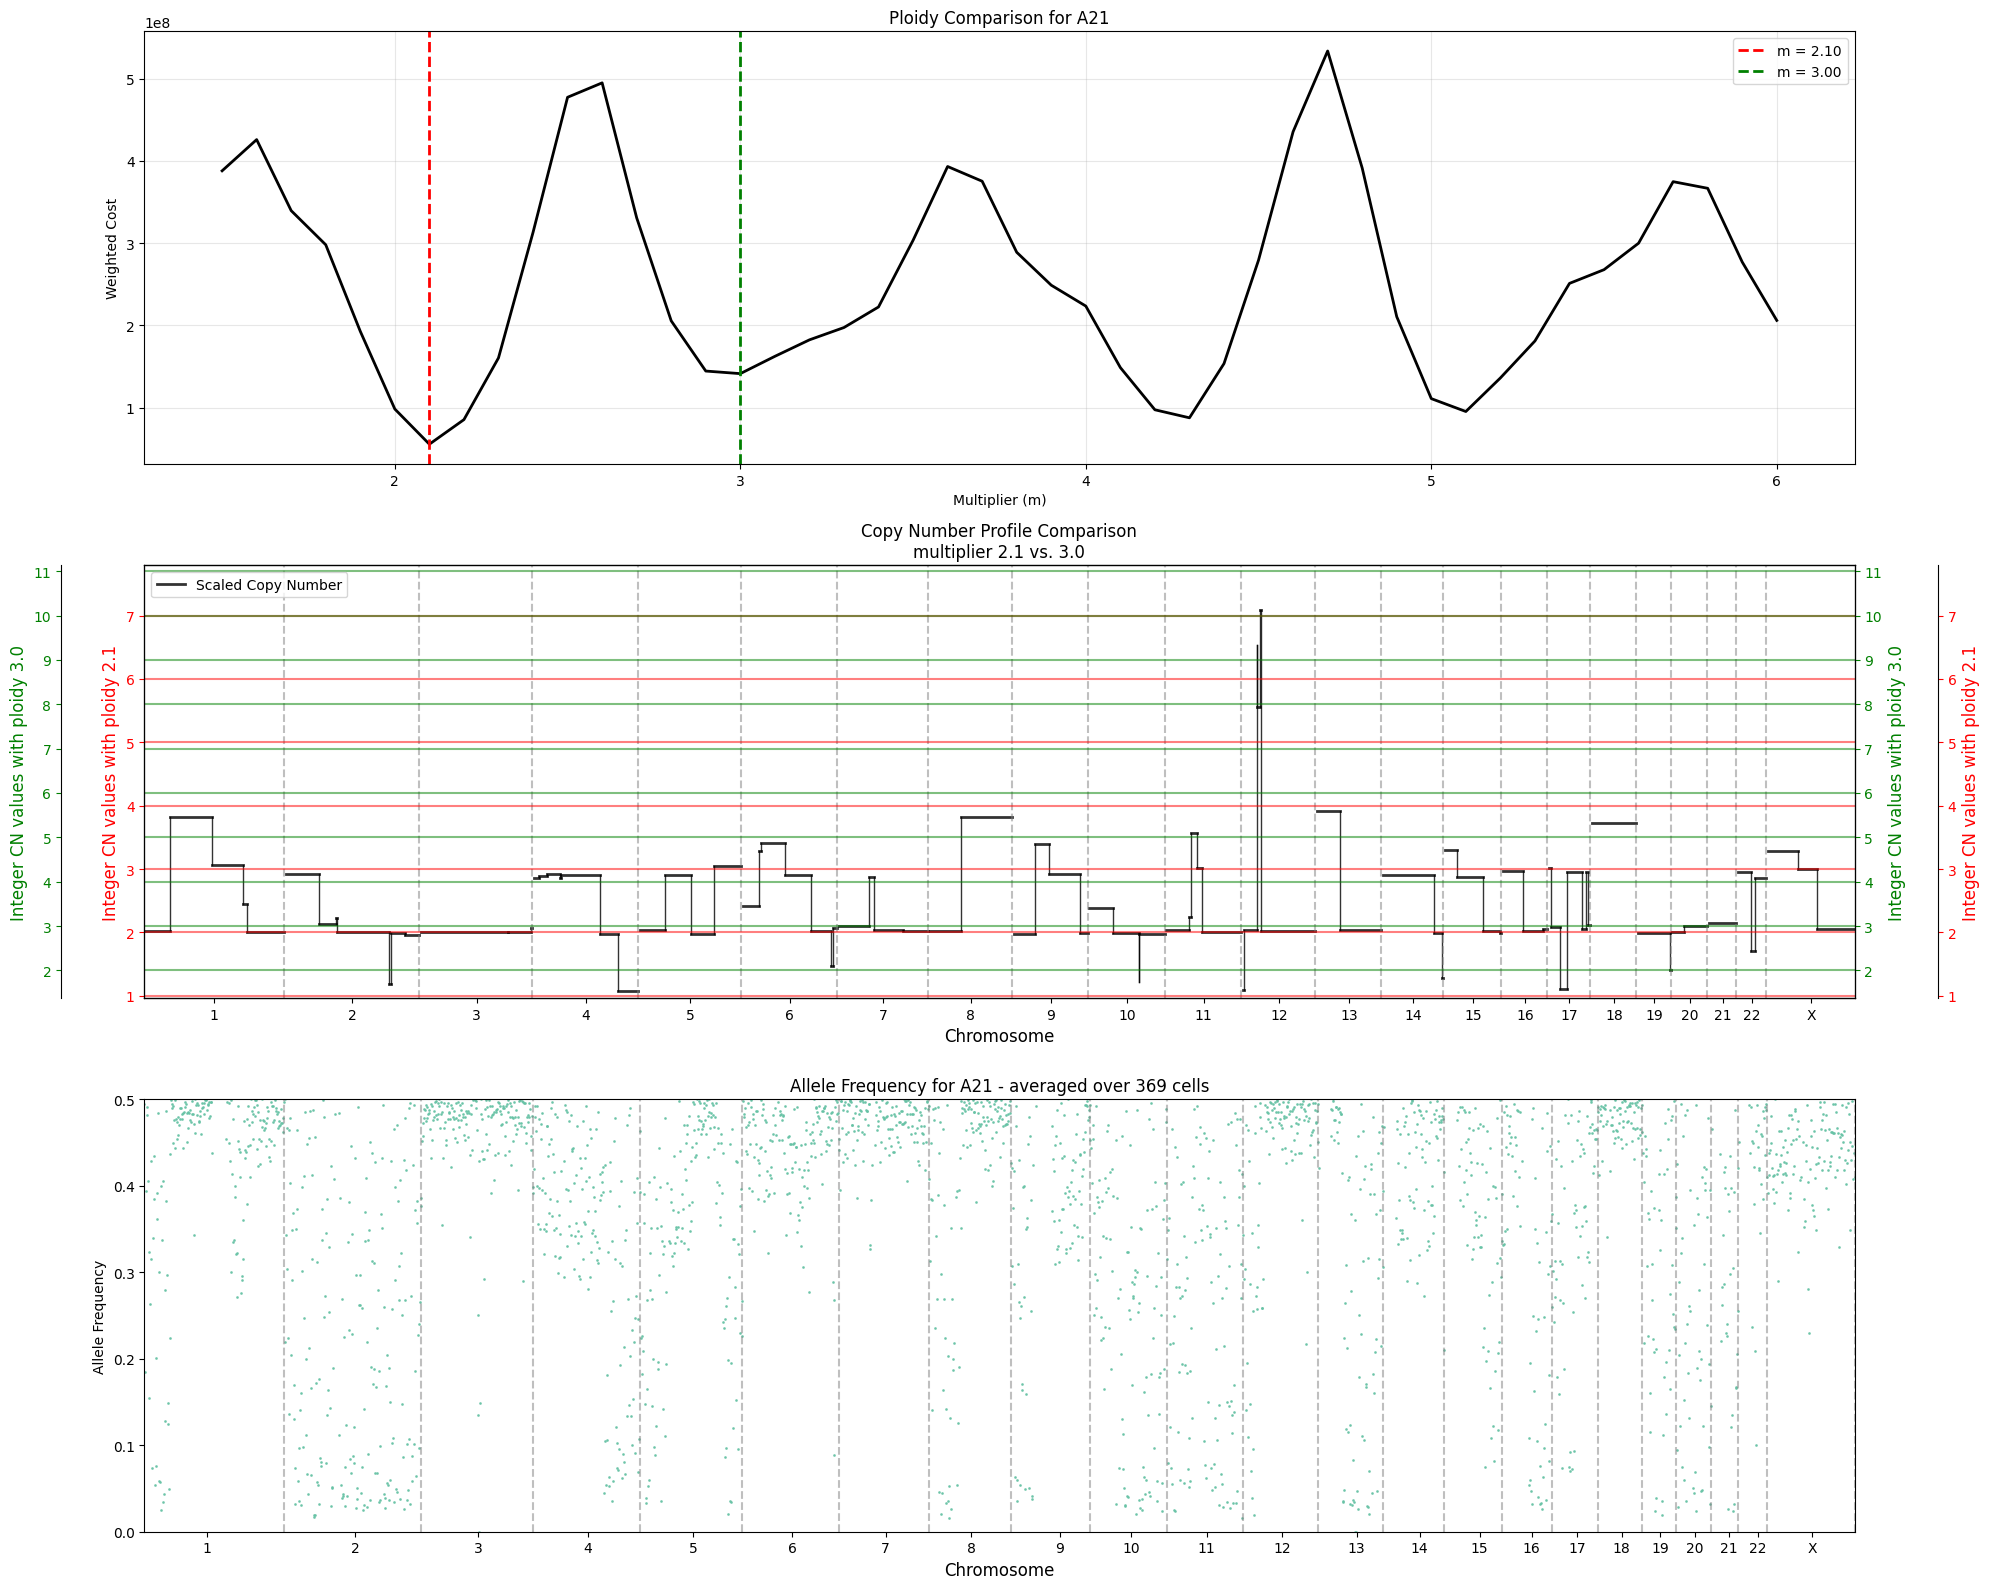


Creating ploidy comparison for population: A2211


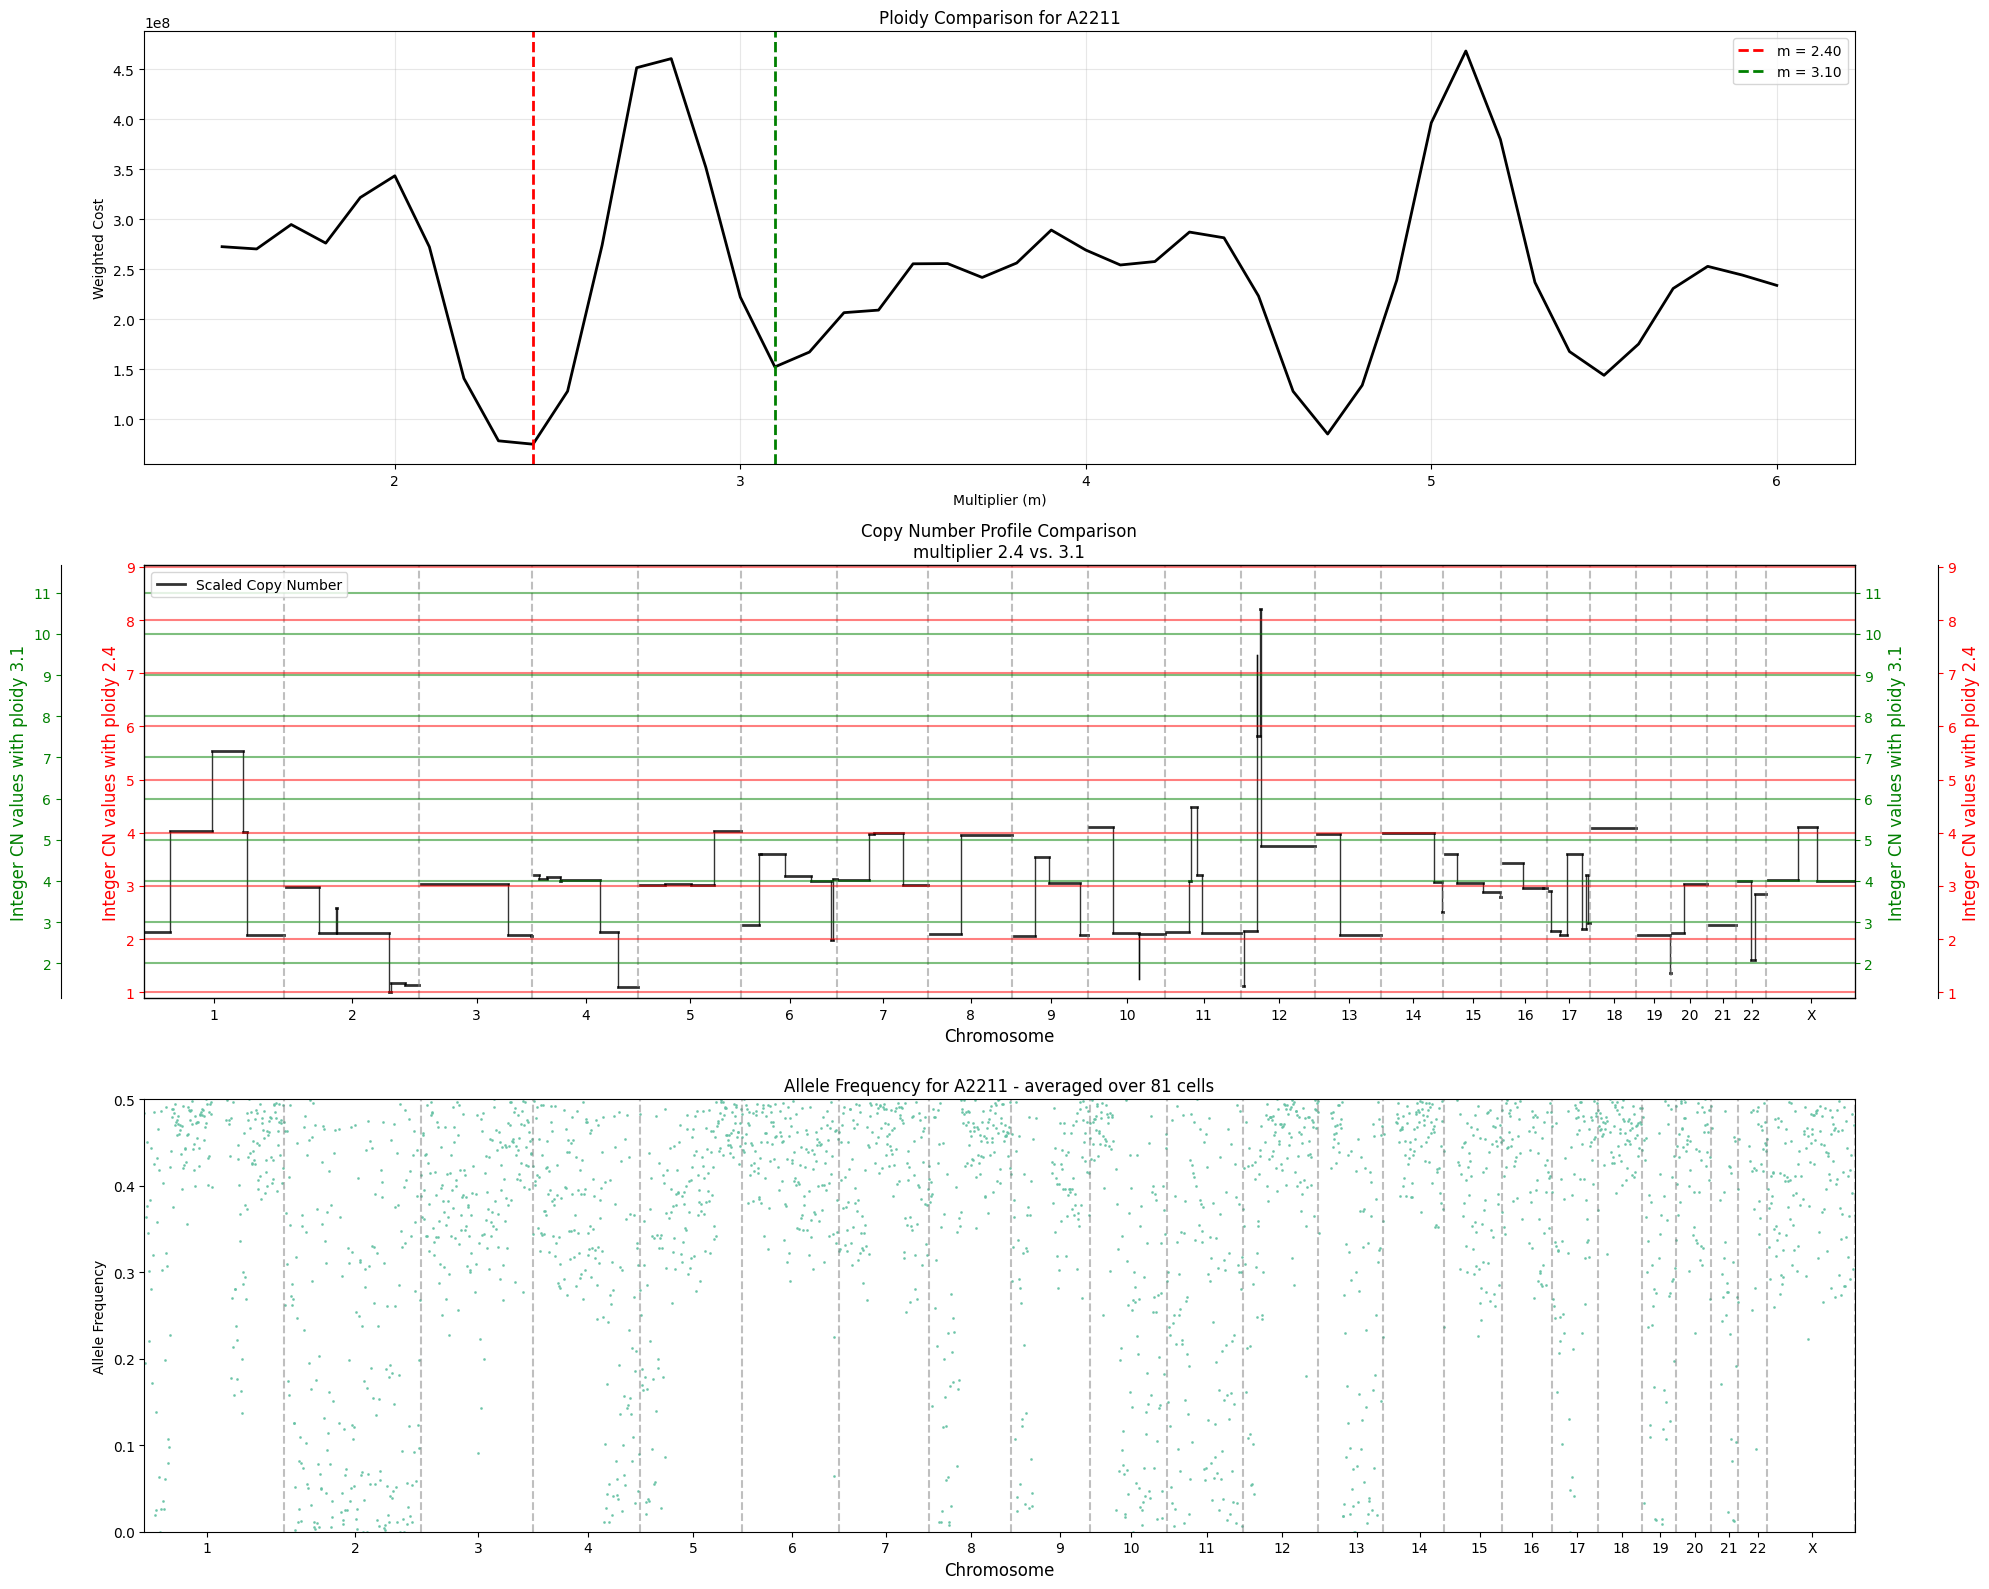


Creating ploidy comparison for population: A2212


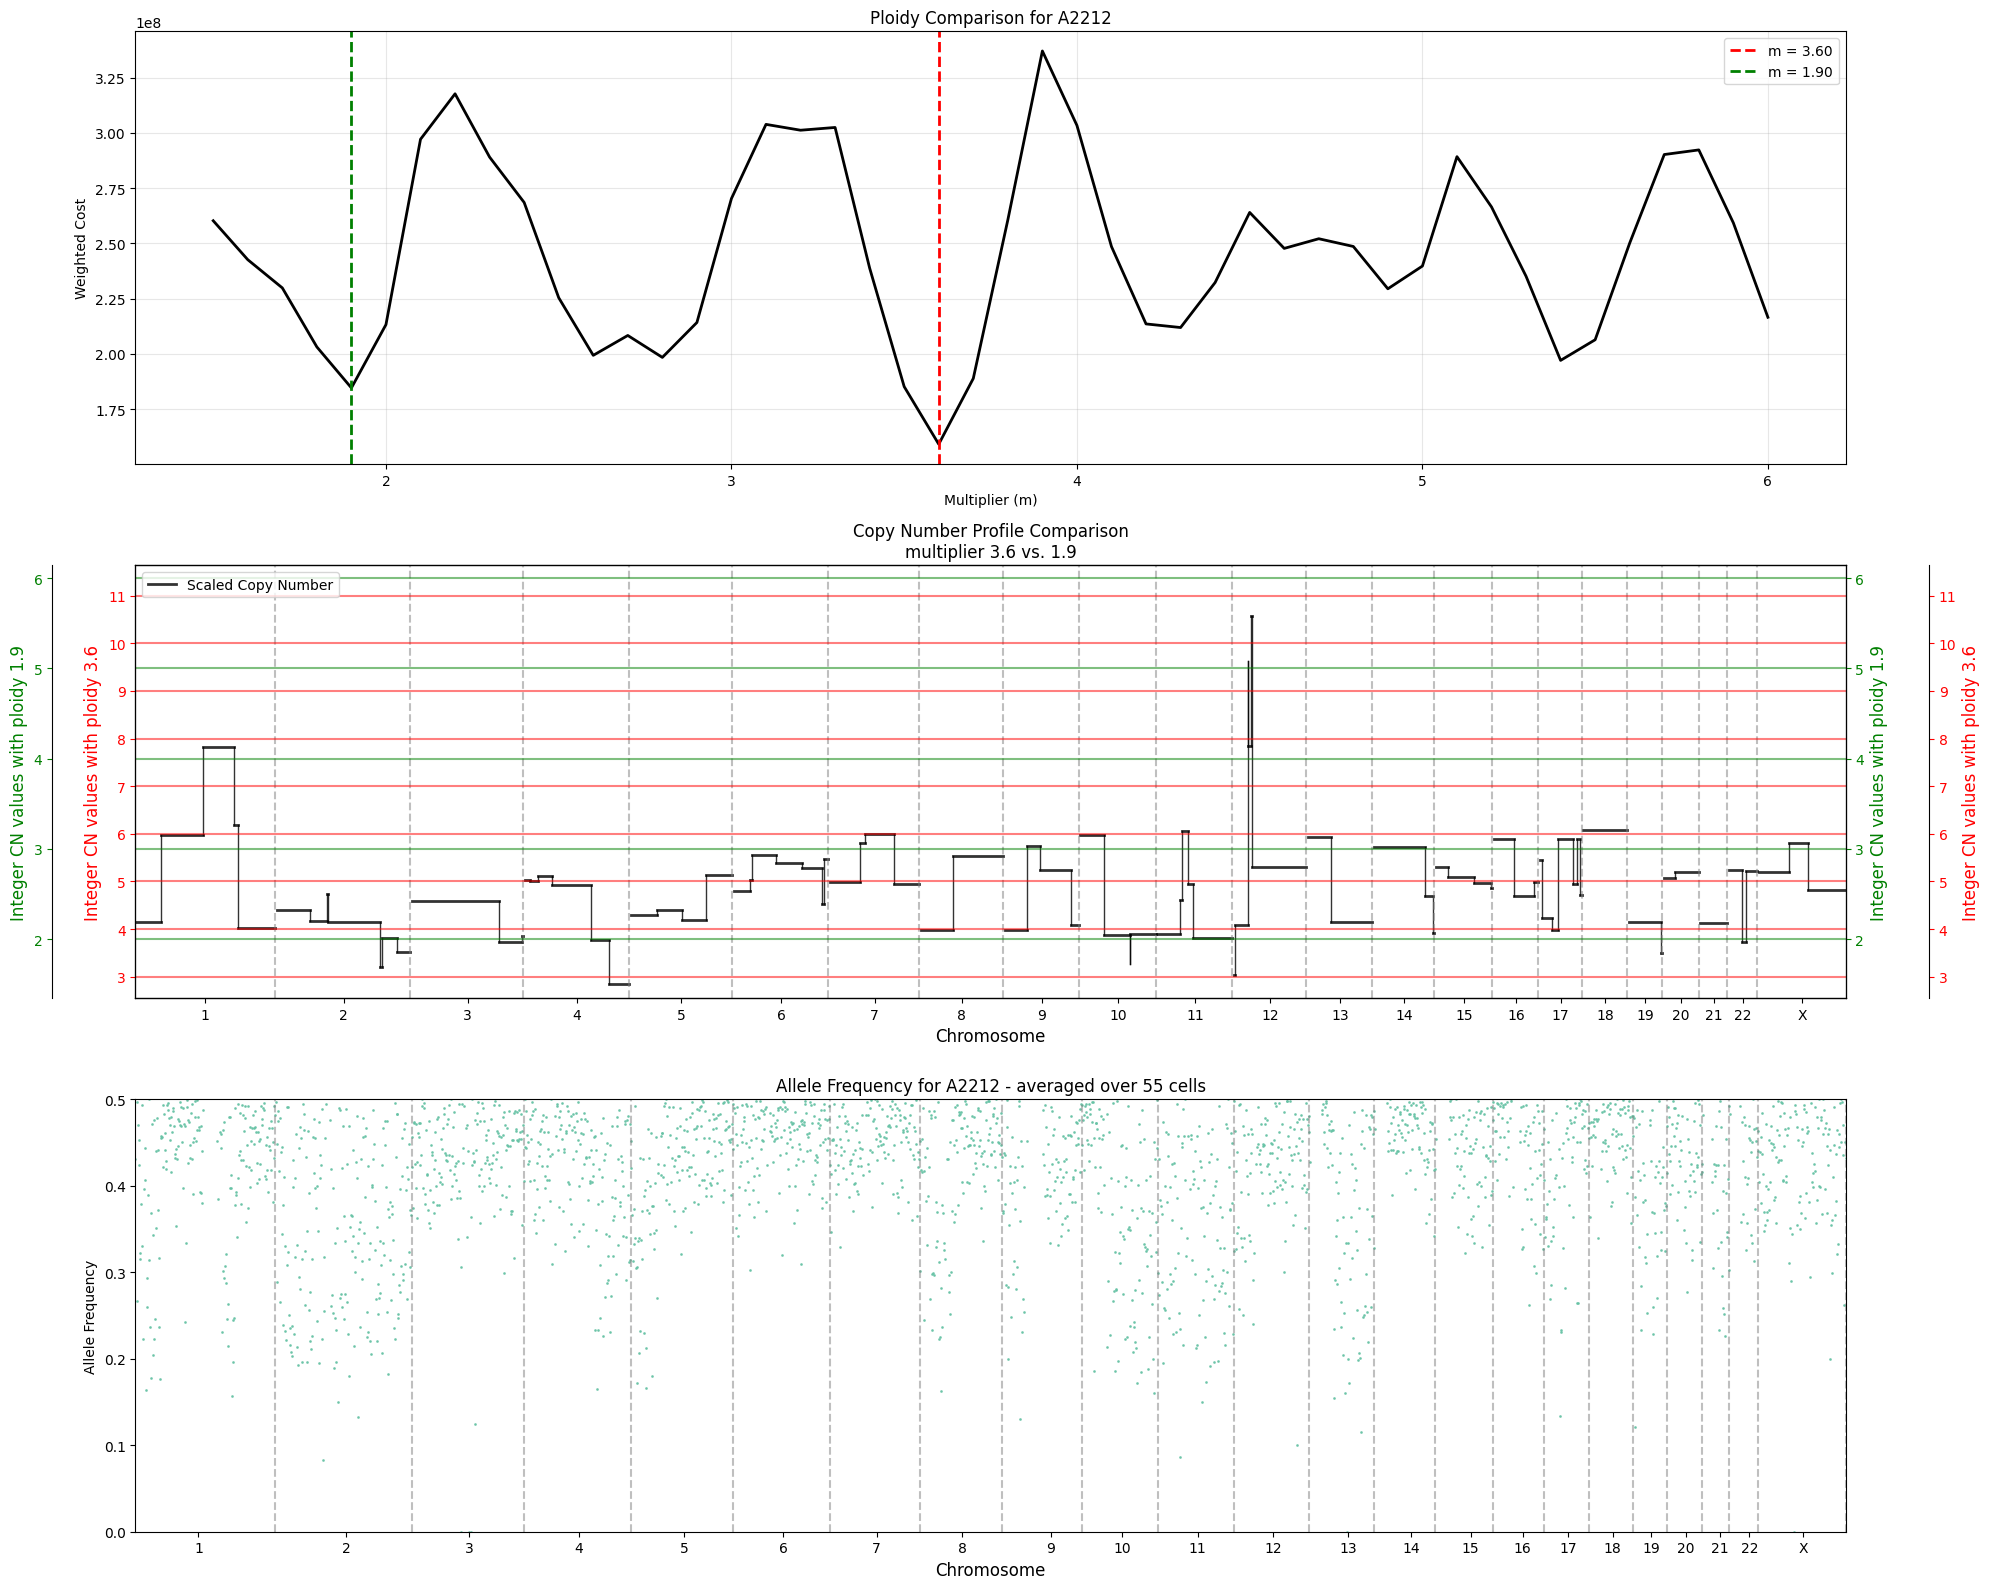


Creating ploidy comparison for population: A2221


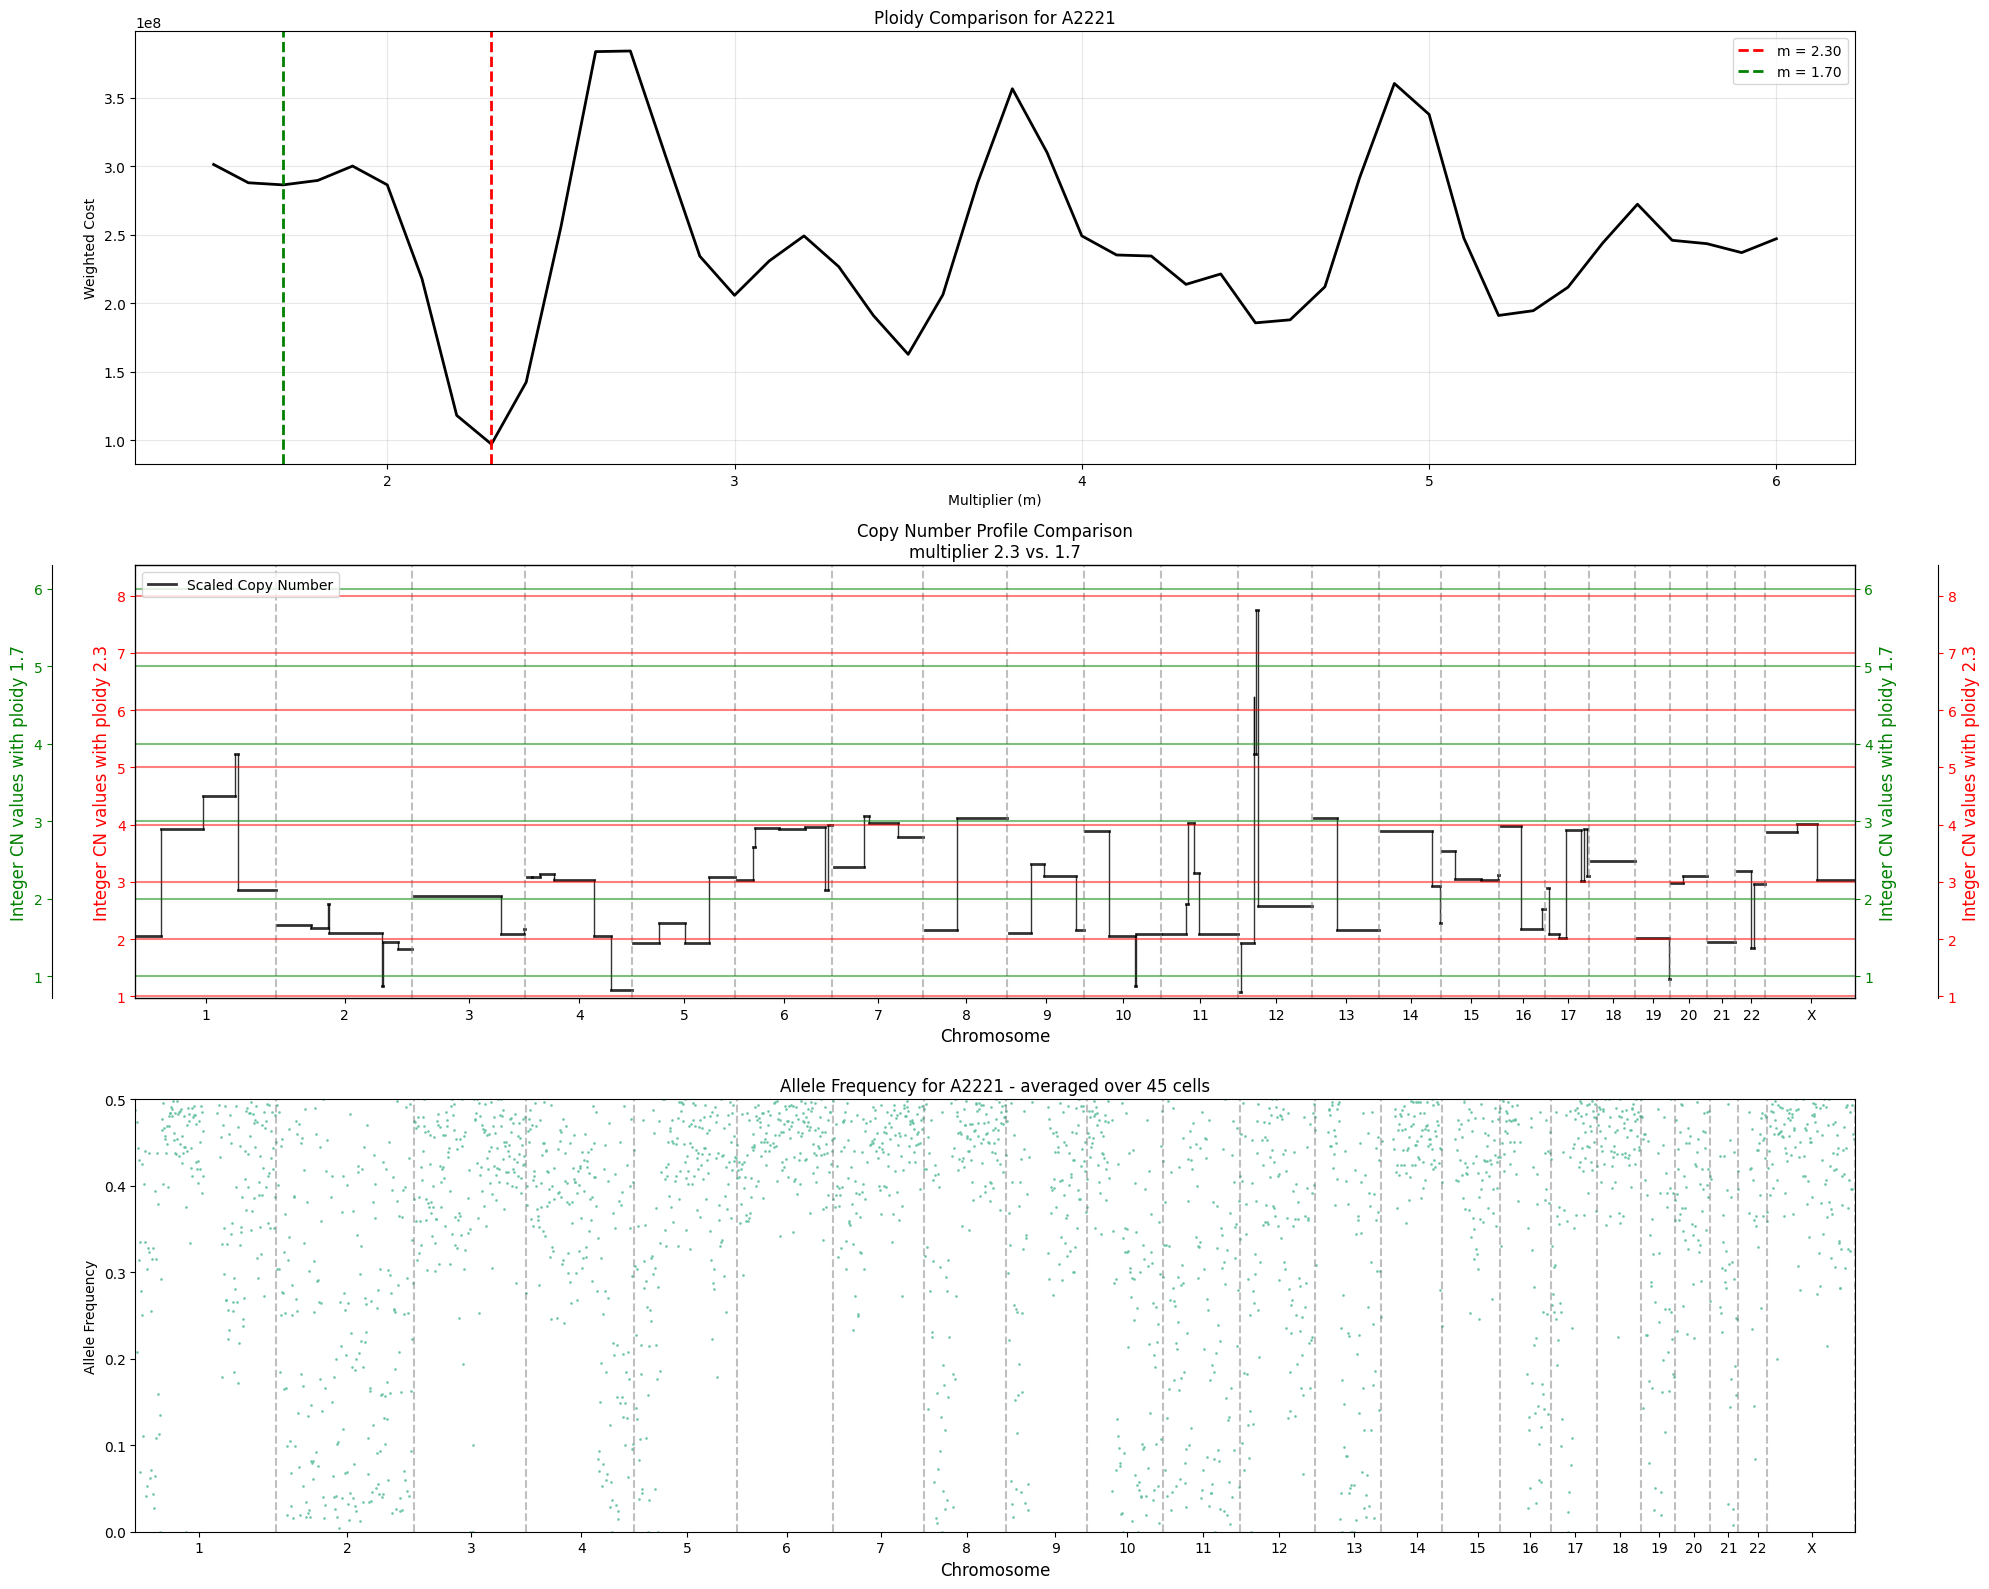


Creating ploidy comparison for population: A22221


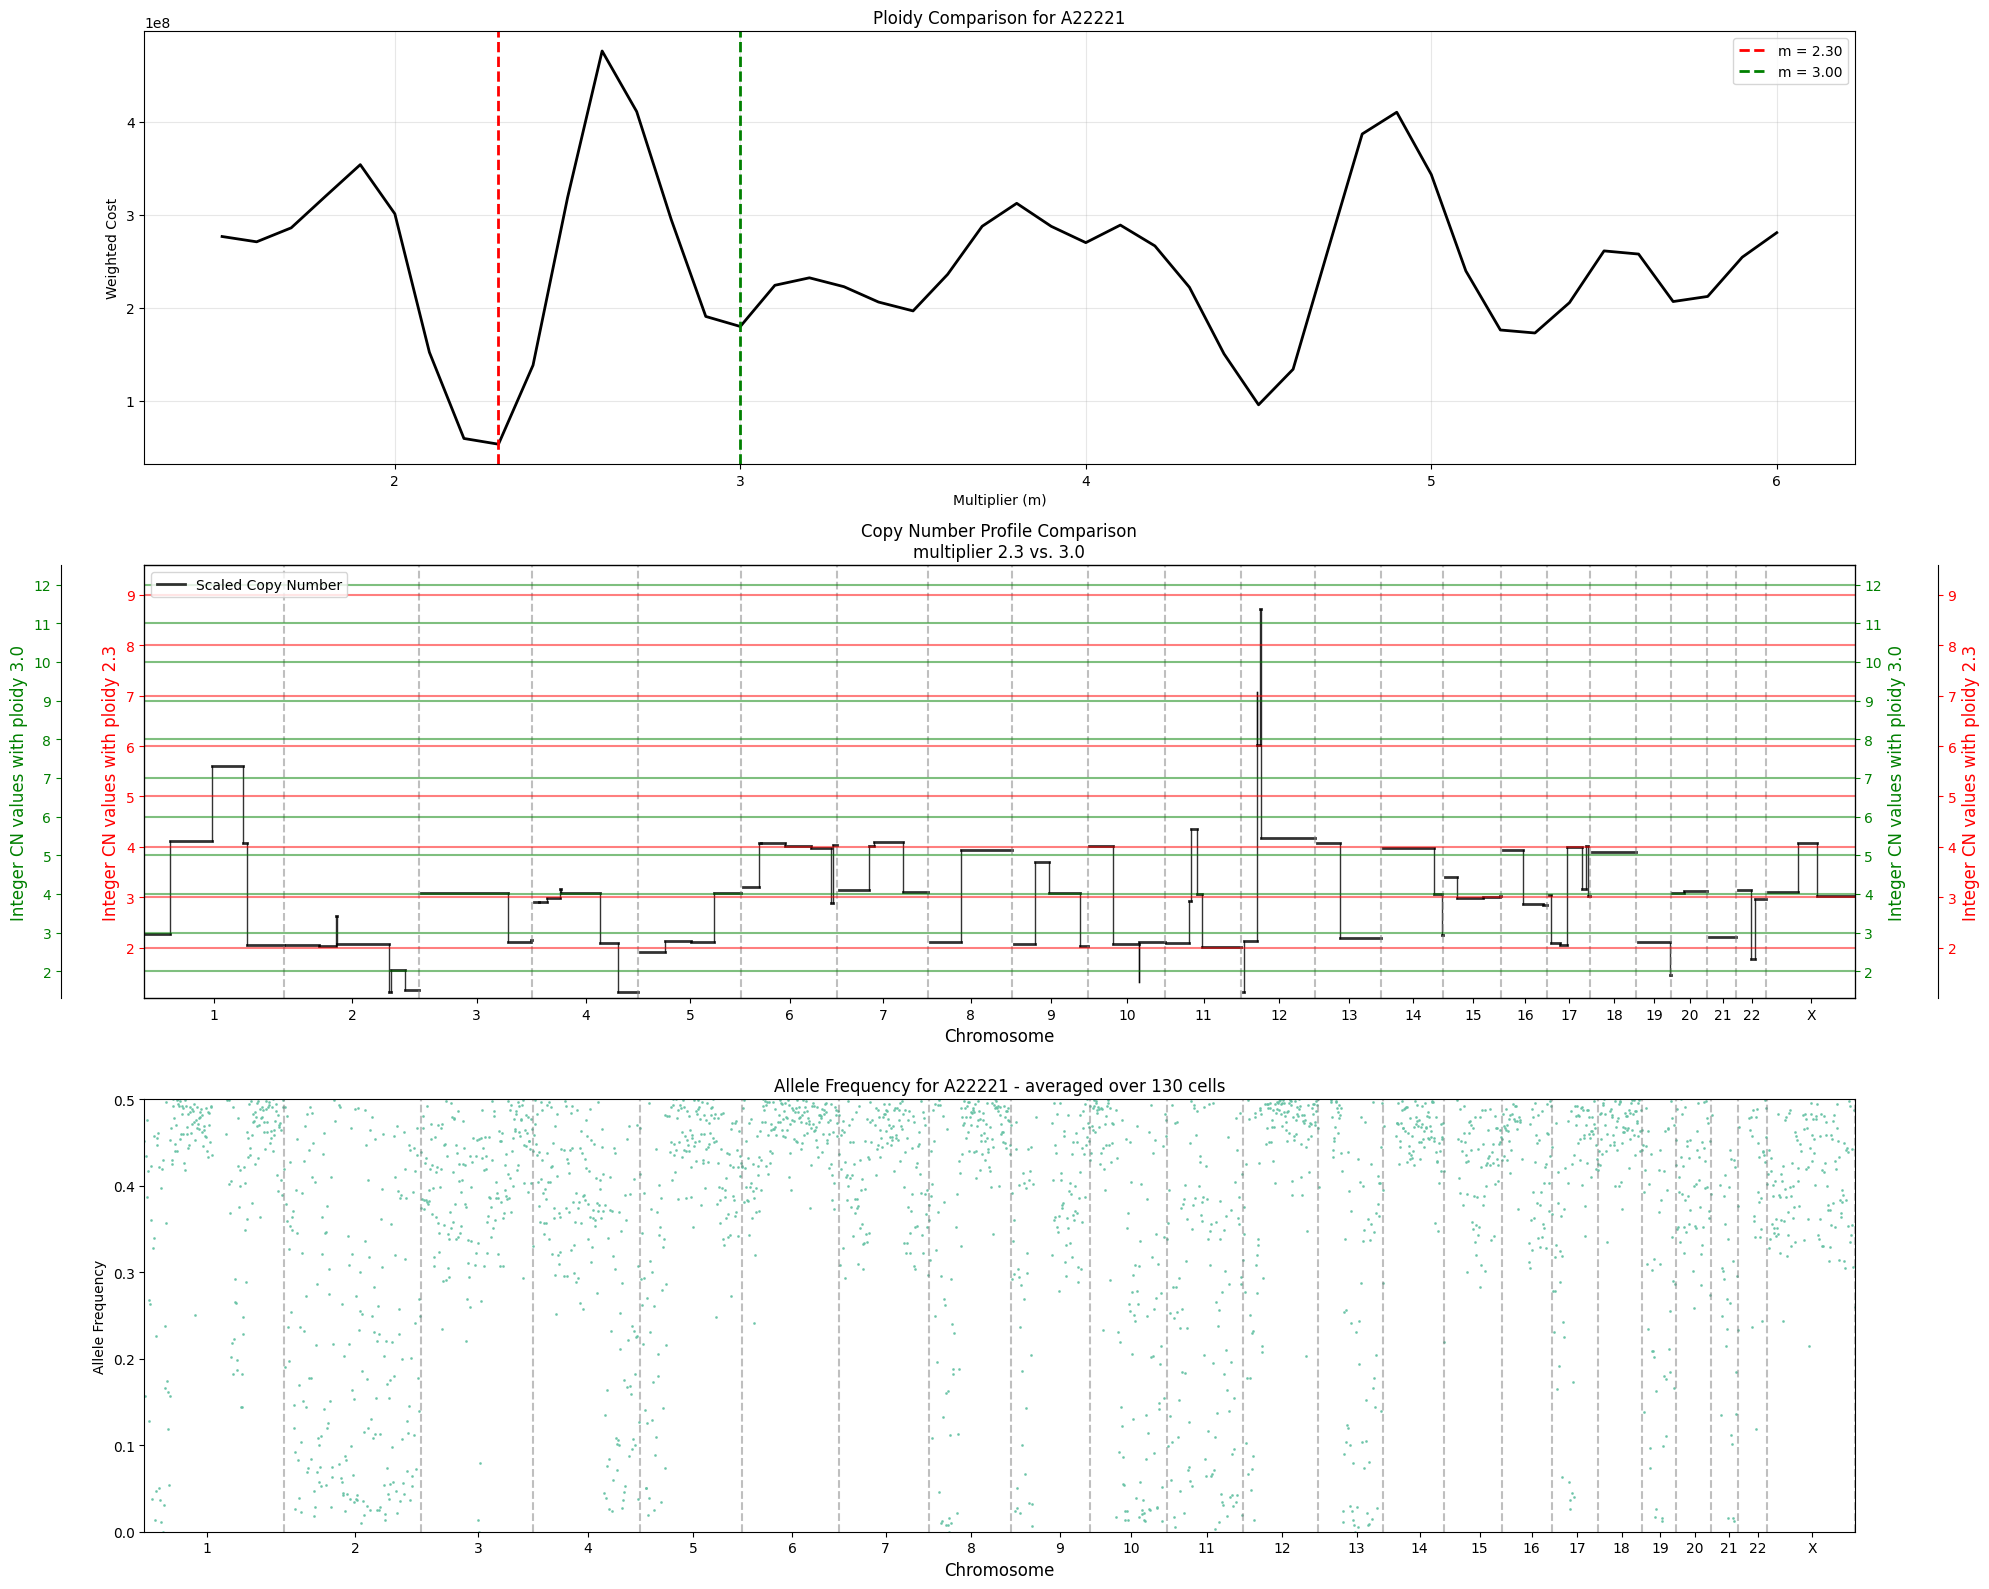


Creating ploidy comparison for population: A222221


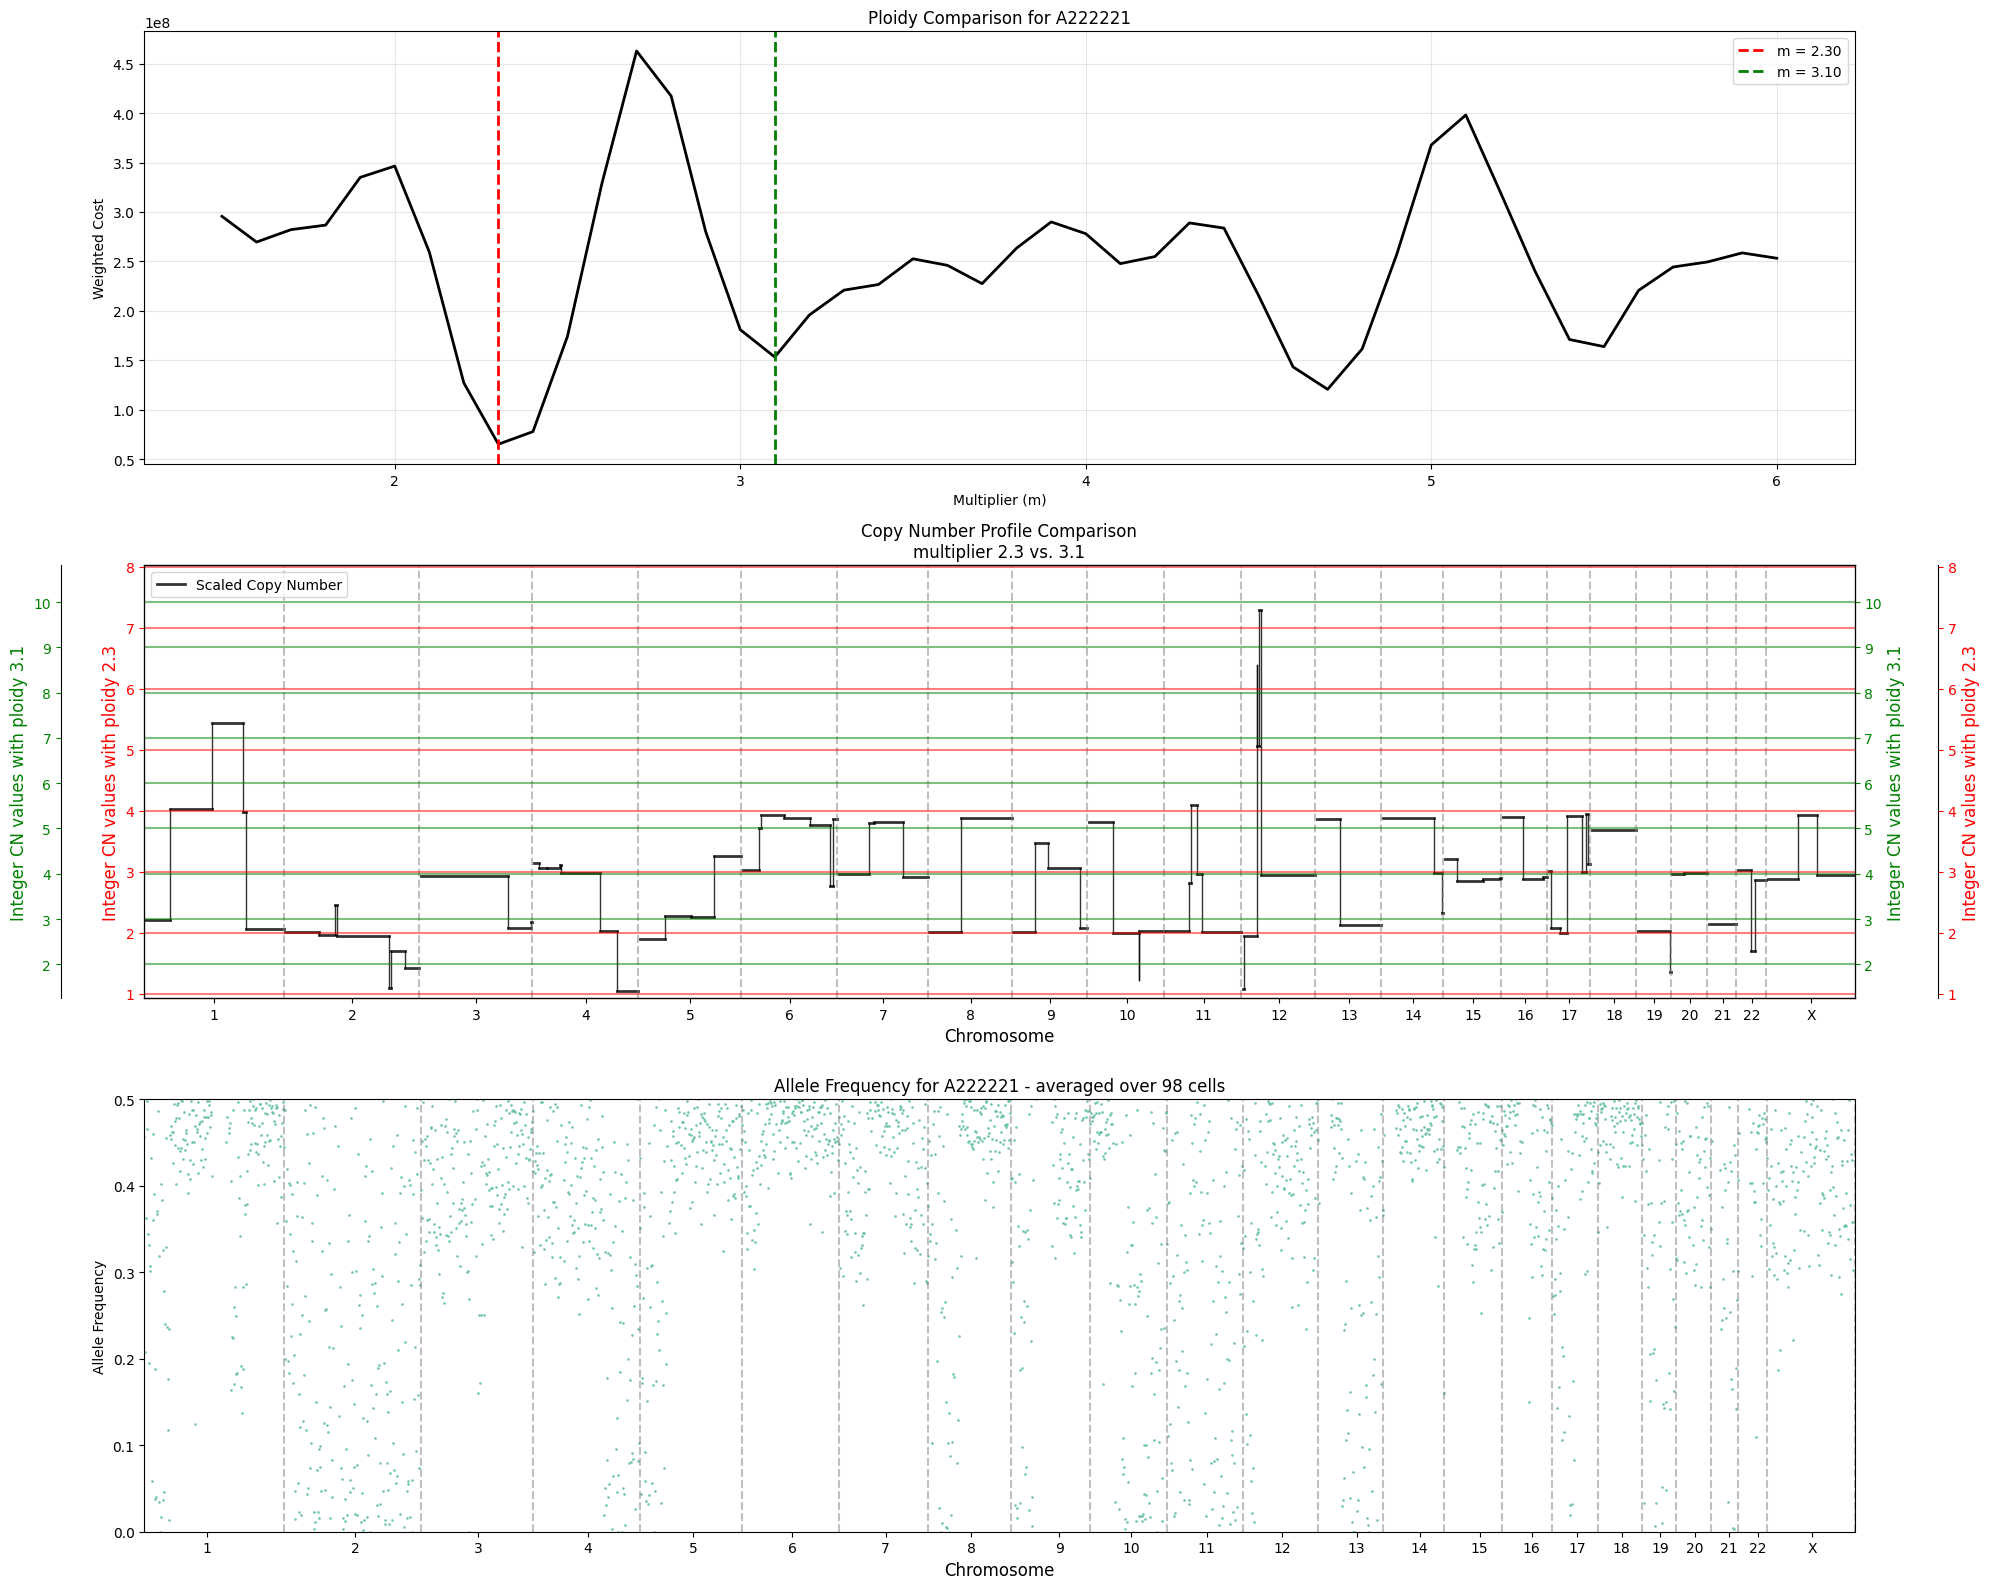


Creating ploidy comparison for population: A222222


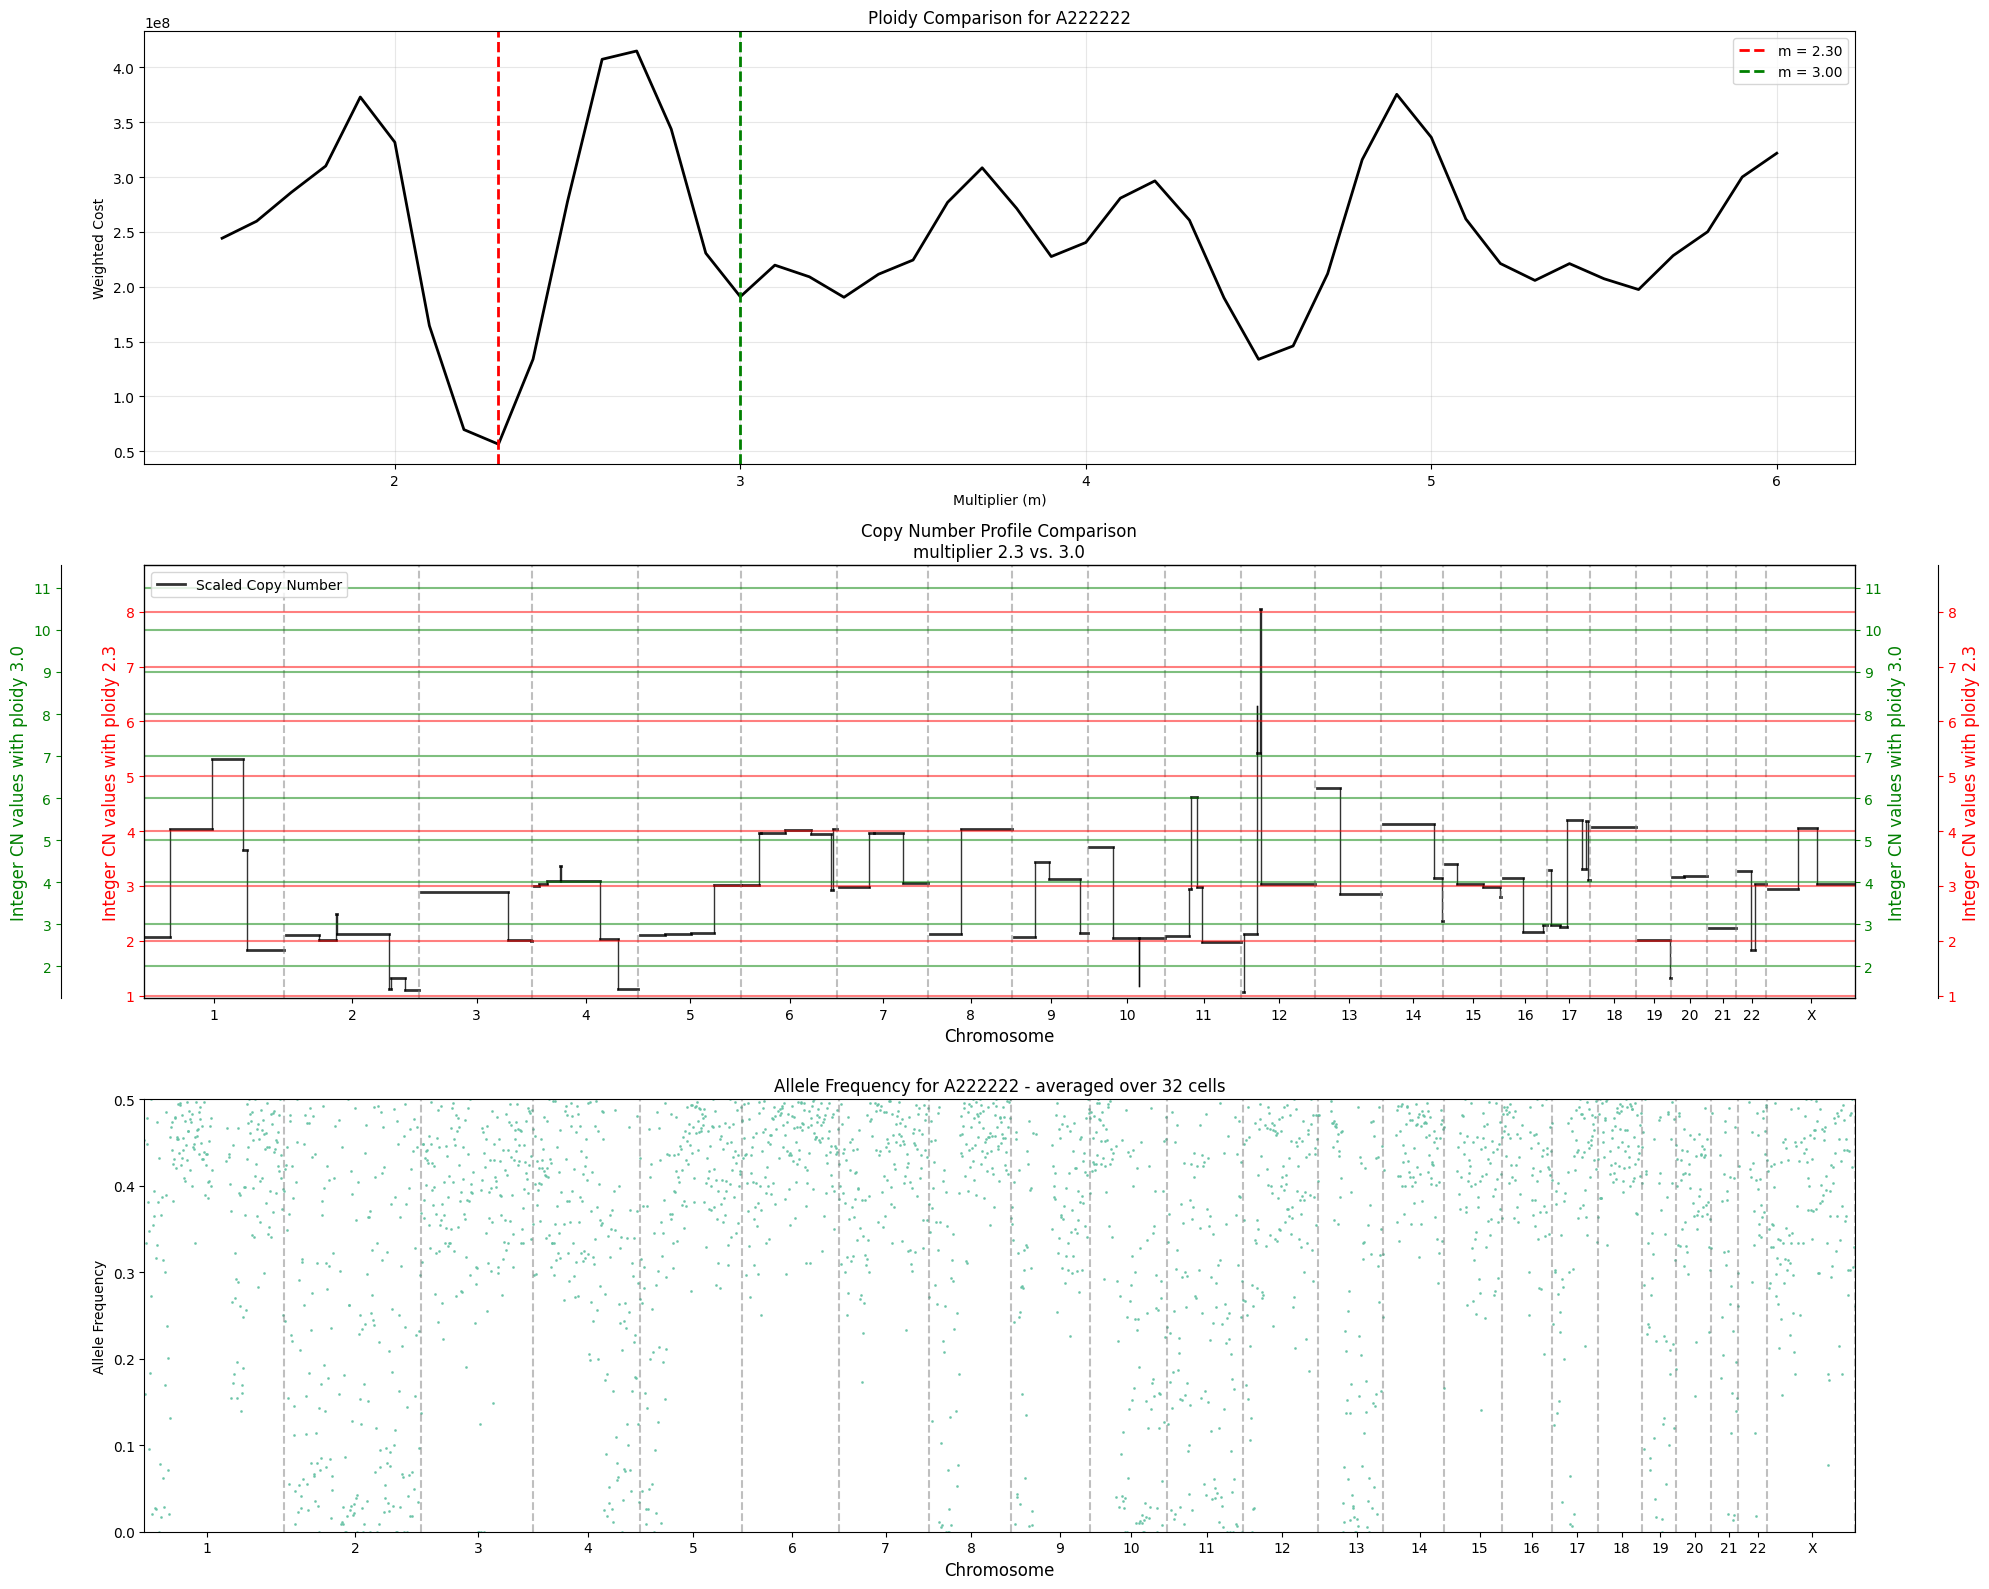

In [20]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    

In [21]:
A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

=== Creating Copy Number Heatmaps ===
Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 89 segments × 2533 cells
Expanding heatmap from 89 segments to 794 rows...

Chromosome representation in heatmap:
chr1: 50 rows, 246,159,932 bp total
chr2: 60 rows, 235,824,599 bp total
chr3: 24 rows, 196,141,480 bp total
chr4: 62 rows, 183,819,298 bp total
chr5: 40 rows, 178,463,482 bp total
chr6: 64 rows, 166,930,960 bp total
chr7: 40 rows, 156,878,815 bp total
chr8: 20 rows, 145,153,934 bp total
chr9: 40 rows, 130,597,528 bp total
chr10: 31 rows, 132,750,269 bp total
chr11: 47 rows, 132,171,512 bp total
chr12: 36 rows, 127,192,322 bp total
chr13: 20 rows, 113,902,193 bp total
chr14: 22 rows, 105,604,444 bp total
chr15: 34 rows, 100,011,182 bp total
chr16: 30 rows, 77,331,877 bp total
chr17: 62 rows, 73,991,953 bp

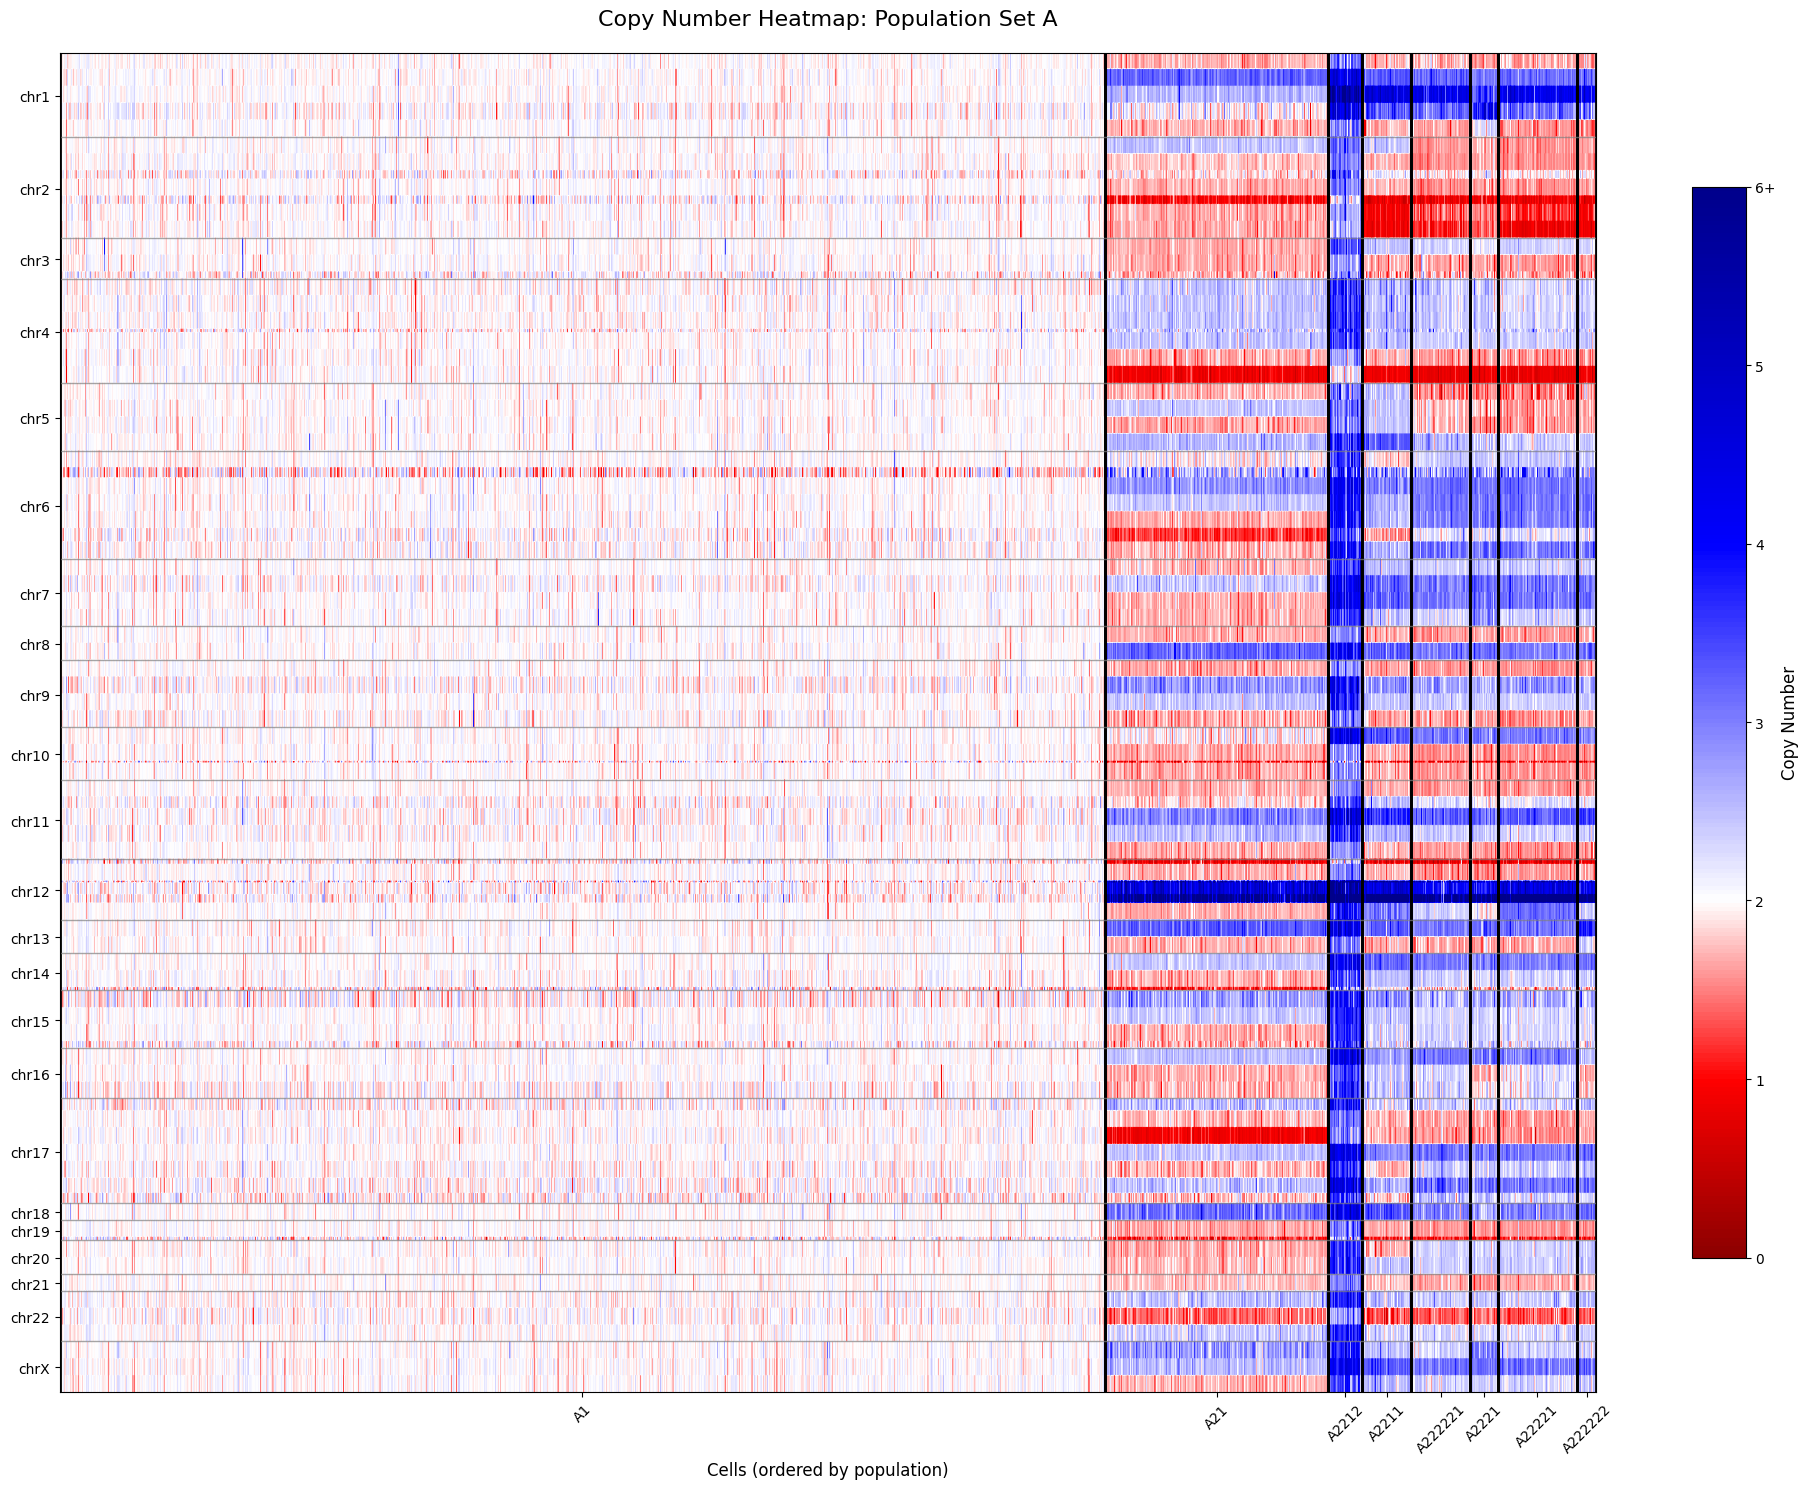

In [22]:
# Add to your imports at the top:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict_reordered, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)
